# Analisis dan Prediksi Harga Komoditas Pangan di Indonesia Berdasarkan Waktu dan Wilayah

### Revisi Portofolio UTS Data Science

**Sumber data:** Dataset PIHPS (Pusat Informasi Harga Pangan Strategis) Nasional, Kaggle
`muhyusuf1112/indonesia-commodity-price-based-piphs-source`


## 0. Konfigurasi Lingkungan dan Reproduksibilitas

Sel di bawah menyiapkan pustaka, jalur direktori, dan parameter global. Seluruh proses
menggunakan *seed* tetap (`42`) dan backend matplotlib non-interaktif (`Agg`) agar notebook dapat
dijalankan tanpa tampilan grafis, misalnya di server atau CI.

In [1]:
import os
import glob
import json
import textwrap
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
np.random.seed(42)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 120)

PROJECT_DIR = Path.cwd()
OUT_DIR     = PROJECT_DIR / "output"
AUDIT_DIR   = OUT_DIR / "audit"
FIG_DIR     = OUT_DIR / "figures"
PROC_DIR    = OUT_DIR / "processed"
for _d in (AUDIT_DIR, FIG_DIR, PROC_DIR):
    _d.mkdir(parents=True, exist_ok=True)

DPI = 300
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": DPI,
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "-",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": False,
})

PALETTE   = {"pasar_modern": "#1f6feb", "pasar_tradisional": "#d29922", "produsen": "#2ea043"}
CH_LABEL  = {"pasar_modern": "Pasar Modern",
             "pasar_tradisional": "Pasar Tradisional",
             "produsen": "Produsen"}
KOM_LABEL = {"beras": "Beras", "bawang_merah": "Bawang Merah", "bawang_putih": "Bawang Putih",
             "cabai_merah": "Cabai Merah", "cabai_rawit": "Cabai Rawit", "daging_ayam": "Daging Ayam",
             "daging_sapi": "Daging Sapi", "gula_pasir": "Gula Pasir",
             "minyak_goreng": "Minyak Goreng", "telur_ayam": "Telur Ayam"}

def fig_path(name):
    return FIG_DIR / name

import io
from IPython.display import display as _display_inline, Image as _InlineImage

def savefig(fig, name):
    # Simpan figur 300 dpi ke disk, lalu tampilkan versi ringan 110 dpi di dalam notebook.
    fig.savefig(fig_path(name), dpi=DPI, bbox_inches="tight", facecolor="white")
    _buf = io.BytesIO()
    fig.savefig(_buf, format="png", dpi=110, bbox_inches="tight", facecolor="white")
    _display_inline(_InlineImage(data=_buf.getvalue(), format="png"))
    plt.close(fig)
    return name

print("Direktori kerja :", PROJECT_DIR)
print("Output          :", OUT_DIR)
print("NumPy           :", np.__version__)
print("pandas          :", pd.__version__)

Direktori kerja : /home/abdillahabhi/Dokumen/Semester 5/Data Science/Teori/Projek Akhir DS
Output          : /home/abdillahabhi/Dokumen/Semester 5/Data Science/Teori/Projek Akhir DS/output
NumPy           : 2.5.2
pandas          : 2.3.3


---
# Bagian A. Business Understanding

## A.1 Latar Belakang

Harga komoditas pangan strategis di Indonesia sangat bergejolak. Lonjakan harga cabai atau
bawang merah dalam hitungan hari dapat menekan daya beli rumah tangga dan menaikkan inflasi
pangan. Pemerintah membutuhkan informasi harga yang cepat, akurat, dan terperinci secara wilayah
agar intervensi seperti Operasi Pasar atau penyaluran Cadangan Pangan Pemerintah dapat dilakukan
secara tepat sasaran, bukan seragam secara nasional.

PIHPS menyediakan data harga harian pada tiga tingkat rantai pasok, yaitu pasar modern, pasar
tradisional, dan produsen, untuk 10 komoditas di 34 provinsi. Namun data mentah tidak langsung
menjawab pertanyaan kebijakan. Diperlukan pengolahan, pembersihan, dan pemodelan agar pola waktu
dan disparitas wilayah dapat dibaca dengan andal.

## A.2 Perumusan Masalah

Berdasarkan latar belakang tersebut, masalah yang dirumuskan adalah:

1. Bagaimana karakteristik dan kualitas data harga pangan PIHPS, termasuk kelengkapan, duplikasi,
   dan anomali nilai?
2. Bagaimana pola harga pangan berdasarkan waktu dan wilayah pada ketiga kanal pasar?
3. Komoditas apa yang paling bergejolak dan paling rentan terhadap guncangan harga?
4. Seberapa besar disparitas harga antarprovinsi, terutama untuk komoditas pangan pokok?
5. Apakah pemodelan dapat mengungguli pembanding sederhana (*naive benchmark*) dalam
   memprediksi harga tujuh hari ke depan?

## A.3 Tujuan

1. Menyusun profil kualitas data dan membersihkannya secara terdokumentasi dan dapat diaudit ulang.
2. Menganalisis pola temporal dan spasial harga pada 10 komoditas di 3 kanal pasar dan 34 provinsi.
3. Mengukur tingkat volatilitas dan disparitas antarwilayah secara kuantitatif.
4. Mempersiapkan dataset bersih dan bebas kebocoran (*leakage-free*) untuk pemodelan deret waktu.

## A.4 Ruang Lingkup dan Pihak Berkepentingan

| Aspek | Batasan |
|---|---|
| Cakupan waktu | 1 Januari 2022 sampai 12 Februari 2026 (1504 hari kalender) |
| Cakupan wilayah | 34 provinsi |
| Komoditas | 10 komoditas pangan strategis |
| Kanal pasar | Pasar modern, pasar tradisional, produsen |
| Unit harga | Rupiah per kilogram, kecuali minyak goreng Rupiah per liter |

| Pemangku kepentingan | Kebutuhan informasi |
|---|---|
| Pemerintah pusat (Bapanas, Kemendag) | Deteksi dini lonjakan harga, dasar Operasi Pasar |
| Pemerintah daerah | Prioritas provinsi dengan harga tertinggi dan disparitas terbesar |
| Bulog dan pelaku distribusi | Pola musiman untuk perencanaan stok |
| Peneliti dan akademisi | Dataset bersih, terdokumentasi, dan dapat direproduksi |

## A.5 Kriteria Keberhasilan

Revisi ini dinyatakan berhasil apabila:

1. Seluruh angka kunci dapat dihitung ulang dari berkas CSV asli, tanpa disalin dari laporan.
2. Setiap aturan pembersihan memiliki bukti jumlah sel yang terdampak dan alasan yang dapat diuji.
3. Tidak ada kebocoran data: seluruh fitur hanya menggunakan informasi sampai waktu `t`, dengan
   target `t+7`.
4. Notebook berjalan dari awal sampai akhir tanpa galat pada lingkungan bersih.

---
# Bagian B. Data Gathering dan Data Understanding

## B.1 Sumber Data

Data diperoleh dari dataset publik Kaggle yang memuat hasil pembersihan dan imputasi PIHPS.
Berkas asli berupa satu arsip ZIP berisi 30 berkas CSV, yaitu 3 kanal pasar x 10 komoditas.

Sel di bawah melakukan pencarian dataset secara berlapis agar notebook tetap dapat dijalankan di
berbagai lingkungan, tanpa bergantung pada satu jalur absolut: (1) direktori lokal hasil ekstraksi,
(2) arsip ZIP yang sudah diunduh, (3) unduhan anonim dari Kaggle, dan (4) unggah manual sebagai
upaya terakhir.

In [2]:
DATA_DIRNAME = "data_komoditas_pangan"

def find_dataset_root(base: Path):
    for cand in [base / DATA_DIRNAME, base / "data" / DATA_DIRNAME]:
        if cand.is_dir():
            csvs = list(cand.rglob("*.csv"))
            if csvs:
                return cand
    return None

def extract_zip(zpath: Path, dest: Path):
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zpath) as zf:
        for m in zf.namelist():
            if m.endswith("/") or ".ipynb_checkpoints" in m:
                continue
            zf.extract(m, dest)
    return dest

def ensure_dataset(base: Path):
    root = find_dataset_root(base)
    if root is not None:
        print(f"[1/4] Dataset ditemukan di direktori lokal: {root}")
        return root

    for zp in [base / "archive.zip"] + sorted(base.glob("*.zip")):
        if zp.exists():
            print(f"[2/4] Mengekstrak arsip lokal: {zp.name}")
            root = find_dataset_root(extract_zip(zp, base))
            if root is not None:
                return root

    try:
        print("[3/4] Mengunduh dataset dari Kaggle (mode anonim) ...")
        import urllib.request
        url = ("https://www.kaggle.com/api/v1/datasets/download/"
               "muhyusuf1112/indonesia-commodity-price-based-piphs-source")
        tmp = base / "archive.zip"
        urllib.request.urlretrieve(url, tmp)
        root = find_dataset_root(extract_zip(tmp, base))
        if root is not None:
            return root
    except Exception as exc:
        print(f"      Unduhan gagal: {exc}")

    try:
        from google.colab import files
        print("[4/4] Silakan unggah archive.zip ...")
        up = files.upload()
        for name in up:
            root = find_dataset_root(extract_zip(base / name, base))
            if root is not None:
                return root
    except Exception:
        pass

    raise FileNotFoundError(
        "Dataset tidak ditemukan. Letakkan folder data_komoditas_pangan atau archive.zip "
        "di direktori notebook."
    )

DATA_ROOT = ensure_dataset(PROJECT_DIR)
CSV_PATHS = sorted(p for p in DATA_ROOT.rglob("*.csv")
                   if ".ipynb_checkpoints" not in str(p) and "final_komoditas_" in p.name)
print(f"\nJumlah berkas CSV : {len(CSV_PATHS)}")
print("Contoh jalur       :", CSV_PATHS[0].relative_to(PROJECT_DIR))

[1/4] Dataset ditemukan di direktori lokal: /home/abdillahabhi/Dokumen/Semester 5/Data Science/Teori/Projek Akhir DS/data_komoditas_pangan

Jumlah berkas CSV : 30
Contoh jalur       : data_komoditas_pangan/pasar_modern/Cleaned_After_Imputation/final_komoditas_modern_bawang_merah_2022_2026.csv


## B.2 Inventarisasi Berkas

Setiap berkas dipetakan ke kanal pasar dan komoditas berdasarkan nama berkasnya. Tabel inventaris
di bawah menjadi bukti cakupan data: 30 berkas yang diharapkan harus lengkap. Berkas yang hilang
akan langsung terlihat sebagai selisih antara 30 dan jumlah berkas terbaca.

In [3]:
CHANNELS  = ["pasar_modern", "pasar_tradisional", "produsen"]
COMMODITY_ORDER = ["beras", "bawang_merah", "bawang_putih", "cabai_merah", "cabai_rawit",
                   "daging_ayam", "daging_sapi", "gula_pasir", "minyak_goreng", "telur_ayam"]

CHANNEL_TOKEN = {"modern": "pasar_modern",
                 "tradisional": "pasar_tradisional",
                 "produsen": "produsen"}

def parse_filename(p: Path):
    # Kanal ditentukan dari nama direktori induk, komoditas dari nama berkas.
    # Nama berkas memakai token pendek (modern, tradisional) yang tidak sama dengan
    # nama kanal pada panel (pasar_modern, pasar_tradisional), sehingga pencocokan
    # berbasis direktori lebih andal daripada pencocokan berbasis nama berkas.
    kom = next((k for k in COMMODITY_ORDER if k in p.stem), None)
    ch = next((c for c in CHANNELS if c in p.parts), None)
    if ch is None:
        for token, kanal in CHANNEL_TOKEN.items():
            if token in p.stem:
                ch = kanal
                break
    return ch, kom

inv_rows = []
for p in CSV_PATHS:
    ch, kom = parse_filename(p)
    if ch is None or kom is None:
        raise ValueError(f"Berkas tidak dapat dipetakan ke kanal/komoditas: {p}")
    df = pd.read_csv(p, nrows=0)
    n_rows = sum(1 for _ in open(p, encoding="utf-8", errors="ignore")) - 1
    inv_rows.append({
        "berkas": p.name,
        "jalur": str(p.relative_to(PROJECT_DIR)),
        "kanal_pasar": ch,
        "komoditas": kom,
        "baris": n_rows,
        "kolom": len(df.columns),
        "ukuran_kb": round(p.stat().st_size / 1024, 1),
    })

inventory = pd.DataFrame(inv_rows).sort_values(["kanal_pasar", "komoditas"]).reset_index(drop=True)
inventory.to_csv(AUDIT_DIR / "data_inventory.csv", index=False)

expected = {(ch, kom) for ch in CHANNELS for kom in COMMODITY_ORDER}
found    = set(zip(inventory["kanal_pasar"], inventory["komoditas"]))
missing  = expected - found

print(f"Berkas terdaftar : {len(inventory)} dari 30 yang diharapkan")
print(f"Berkas hilang    : {len(missing)}" + (f" -> {sorted(missing)}" if missing else ""))
print(f"Total baris mentah: {inventory['baris'].sum():,}")
print(f"Total ukuran      : {inventory['ukuran_kb'].sum()/1024:.2f} MB")
print()
display(inventory.pivot_table(index="komoditas", columns="kanal_pasar", values="baris",
                              aggfunc="first").reindex(COMMODITY_ORDER))

Berkas terdaftar : 30 dari 30 yang diharapkan
Berkas hilang    : 0
Total baris mentah: 44,014
Total ukuran      : 11.28 MB



kanal_pasar,pasar_modern,pasar_tradisional,produsen
komoditas,,,
beras,1493,1415,1493
bawang_merah,1493,1415,1493
bawang_putih,1493,1415,1493
cabai_merah,1493,1417,1493
cabai_rawit,1493,1417,1493
daging_ayam,1493,1415,1493
daging_sapi,1493,1415,1493
gula_pasir,1493,1415,1493
minyak_goreng,1493,1415,1493


## B.3 Audit Kualitas Data Mentah

Sebelum analisis apa pun, kualitas data harus diukur, bukan diasumsikan. Audit ini menghitung enam
dimensi: jumlah baris, jumlah kolom provinsi, nilai kosong, nilai negatif atau nol, duplikat, dan
rentang tanggal.

Perlu dicatat bahwa berkas sumber bernama `Cleaned_After_Imputation`. Nama tersebut mengundang
asumsi bahwa data sudah bebas masalah. Audit di bawah menguji asumsi itu.

In [4]:
audit_rows = []
frames = {}

for _, row in inventory.iterrows():
    ch, kom, path = row["kanal_pasar"], row["komoditas"], PROJECT_DIR / row["jalur"]
    df = pd.read_csv(path)

    prov_cols = [c for c in df.columns if c != "Date_Param"]
    df["Date_Param"] = pd.to_datetime(df["Date_Param"], errors="coerce")
    vals = df[prov_cols].apply(pd.to_numeric, errors="coerce")

    n_cells   = vals.size
    n_nan     = int(vals.isna().sum().sum())
    n_nonpos  = int((vals <= 0).sum().sum())
    n_dup_rows = int(df.duplicated(subset=["Date_Param"]).sum())

    audit_rows.append({
        "kanal_pasar": ch,
        "komoditas": kom,
        "baris": len(df),
        "kolom_provinsi": len(prov_cols),
        "sel_nilai": n_cells,
        "sel_kosong": n_nan,
        "pct_kosong": round(100 * n_nan / n_cells, 3),
        "sel_non_positif": n_nonpos,
        "duplikat_tanggal": n_dup_rows,
        "tanggal_min": df["Date_Param"].min().date(),
        "tanggal_max": df["Date_Param"].max().date(),
        "hari_unik": df["Date_Param"].nunique(),
    })
    frames[(ch, kom)] = (df, prov_cols)

audit = pd.DataFrame(audit_rows)
audit.to_csv(AUDIT_DIR / "data_quality_report.csv", index=False)

tot_cells = int(audit["sel_nilai"].sum())
tot_nan   = int(audit["sel_kosong"].sum())
print(f"Total sel nilai        : {tot_cells:,}")
print(f"Total sel kosong       : {tot_nan:,} ({100*tot_nan/tot_cells:.4f}%)")
print(f"Total sel non-positif  : {int(audit['sel_non_positif'].sum())}")
print(f"Total duplikat tanggal : {int(audit['duplikat_tanggal'].sum())}")
print(f"Rentang tanggal        : {audit['tanggal_min'].min()} s.d. {audit['tanggal_max'].max()}")
print(f"Jumlah hari kalender   : {(pd.Timestamp(audit['tanggal_max'].max()) - pd.Timestamp(audit['tanggal_min'].min())).days + 1}")
print()
display(audit[["kanal_pasar","komoditas","baris","kolom_provinsi","sel_kosong","pct_kosong",
               "sel_non_positif","duplikat_tanggal","hari_unik"]].head(12))

Total sel nilai        : 1,354,641
Total sel kosong       : 0 (0.0000%)
Total sel non-positif  : 0
Total duplikat tanggal : 0
Rentang tanggal        : 2022-01-01 s.d. 2026-02-12
Jumlah hari kalender   : 1504



,kanal_pasar,komoditas,baris,kolom_provinsi,sel_kosong,pct_kosong,sel_non_positif,duplikat_tanggal,hari_unik
0,pasar_modern,bawang_merah,1493,34,0,0.0,0,0,1493
1,pasar_modern,bawang_putih,1493,34,0,0.0,0,0,1493
2,pasar_modern,beras,1493,34,0,0.0,0,0,1493
3,pasar_modern,cabai_merah,1493,34,0,0.0,0,0,1493
4,pasar_modern,cabai_rawit,1493,34,0,0.0,0,0,1493
5,pasar_modern,daging_ayam,1493,33,0,0.0,0,0,1493
6,pasar_modern,daging_sapi,1493,32,0,0.0,0,0,1493
7,pasar_modern,gula_pasir,1493,34,0,0.0,0,0,1493
8,pasar_modern,minyak_goreng,1493,34,0,0.0,0,0,1493
9,pasar_modern,telur_ayam,1493,34,0,0.0,0,0,1493


### B.3.1 Interpretasi Audit Awal

Audit di atas menegaskan satu hal penting: nama berkas `Cleaned_After_Imputation` **tidak**
menjamin data bebas masalah. Meskipun tidak ada sel kosong dan tidak ada duplikat, keterbatasan
yang tersisa justru lebih berbahaya karena tidak terlihat:

- **Nilai kosong nol bukan berarti data lengkap.** Nilai hilang telah diisi oleh proses imputasi
  di hulu. Sisa-sisa imputasi ini muncul sebagai pola anomali yang harus dideteksi, bukan dianggap
  sebagai data pengamatan asli.
- **Jumlah hari unik lebih kecil dari hari kalender.** Artinya terdapat tanggal yang tidak
  teramati. Ketiadaan ini tidak diisi secara eksplisit dan harus ditangani pada tahap
  preprocessing.
- **Tidak ada kolom satuan.** Satuan harus diturunkan dari domain pengetahuan: minyak goreng dalam
  Rupiah per liter, sembilan komoditas lain dalam Rupiah per kilogram. Tanpa penegasan ini, agregasi
  lintas komoditas menjadi tidak bermakna.

Selanjutnya data diubah dari bentuk lebar (*wide*) menjadi format panjang (*long*) agar dapat
dianalisis sebagai deret waktu panel.

## B.4 Pembentukan Panel Data (Wide ke Long)

Bentuk lebar (satu kolom per provinsi) nyaman untuk penyimpanan, tetapi tidak nyaman untuk
analisis. Format panjang (*long* / *tidy*) memungkinkan pengelompokan (`groupby`) dan agregasi
yang konsisten.

Aturan turunan satuan ditetapkan sebagai berikut:

- `minyak_goreng` diukur dalam **Rupiah per liter**, karena dijual dalam kemasan volume.
- Sembilan komoditas lain diukur dalam **Rupiah per kilogram**.

Tanpa penegasan ini, nilai minyak goreng tidak sebanding dengan komoditas lain dan akan
mencemari statistik gabungan.

In [5]:
UNIT_BY_COMMODITY = {k: "Rp/kg" for k in COMMODITY_ORDER}
UNIT_BY_COMMODITY["minyak_goreng"] = "Rp/liter"

panel_parts = []
for (ch, kom), (df, prov_cols) in frames.items():
    long = df.melt(id_vars="Date_Param", value_vars=prov_cols,
                   var_name="Provinsi", value_name="Harga")
    long["Kanal_Pasar"] = ch
    long["Komoditas"]   = kom
    long["Satuan"]      = UNIT_BY_COMMODITY[kom]
    panel_parts.append(long)

panel = (pd.concat(panel_parts, ignore_index=True)
           .rename(columns={"Date_Param": "Date"})
           .dropna(subset=["Date"])
           .astype({"Harga": "float64"}))

panel["Provinsi"]   = panel["Provinsi"].str.strip()
panel["Kanal_Pasar"] = pd.Categorical(panel["Kanal_Pasar"], categories=CHANNELS, ordered=True)
panel["Komoditas"]   = pd.Categorical(panel["Komoditas"], categories=COMMODITY_ORDER, ordered=True)
panel = panel[["Date", "Kanal_Pasar", "Komoditas", "Provinsi", "Satuan", "Harga"]]
panel = panel.sort_values(["Kanal_Pasar", "Komoditas", "Provinsi", "Date"]).reset_index(drop=True)

panel.to_parquet(PROC_DIR / "_panel_raw.parquet", index=False)

print(f"Baris panel        : {len(panel):,}")
print(f"Kanal pasar        : {panel['Kanal_Pasar'].nunique()}")
print(f"Komoditas          : {panel['Komoditas'].nunique()}")
print(f"Provinsi           : {panel['Provinsi'].nunique()}")
print(f"Deret (kanal x kom x prov): {panel.groupby(['Kanal_Pasar','Komoditas','Provinsi'], observed=True).ngroups:,}")
print()
print("Sebaran observasi per kanal:")
print(panel["Kanal_Pasar"].value_counts().sort_index().to_string())

Baris panel        : 1,354,641
Kanal pasar        : 3
Komoditas          : 10
Provinsi           : 34
Deret (kanal x kom x prov): 925

Sebaran observasi per kanal:
Kanal_Pasar
pasar_modern         503141
pasar_tradisional    481236
produsen             370264


## B.5 Struktur dan Kamus Data

Tabel berikut merangkum setiap kolom dalam panel beserta tipe, satuan, dan maknanya. Kamus data
ini penting agar pembaca tidak salah menafsirkan, khususnya pada kolom `Harga` yang satuannya
berbeda untuk minyak goreng.

In [6]:
kamus = pd.DataFrame([
    ("Date",        "datetime64[ns]", "Tanggal pencatatan harga", "hari"),
    ("Kanal_Pasar", "category", "Tingkat rantai pasok pencatatan", "pasar_modern / pasar_tradisional / produsen"),
    ("Komoditas",   "category", "Nama komoditas pangan strategis", "10 komoditas"),
    ("Provinsi",    "object",   "Provinsi lokasi pencatatan", "34 provinsi"),
    ("Satuan",      "object",   "Satuan harga sesuai komoditas", "Rp/kg atau Rp/liter"),
    ("Harga",       "float64",  "Harga nominal tercatat", "Rupiah"),
], columns=["kolom", "tipe", "deskripsi", "nilai_valid"])

display(kamus)

print("Daftar provinsi (%d):" % panel["Provinsi"].nunique())
for i, prov in enumerate(sorted(panel["Provinsi"].unique()), start=1):
    print(f"{i:2d}. {prov}")

,kolom,tipe,deskripsi,nilai_valid
0,Date,datetime64[ns],Tanggal pencatatan harga,hari
1,Kanal_Pasar,category,Tingkat rantai pasok pencatatan,pasar_modern / pasar_tradisional / produsen
2,Komoditas,category,Nama komoditas pangan strategis,10 komoditas
3,Provinsi,object,Provinsi lokasi pencatatan,34 provinsi
4,Satuan,object,Satuan harga sesuai komoditas,Rp/kg atau Rp/liter
5,Harga,float64,Harga nominal tercatat,Rupiah


Daftar provinsi (34):
 1. Aceh
 2. Bali
 3. Banten
 4. Bengkulu
 5. DI Yogyakarta
 6. DKI Jakarta
 7. Gorontalo
 8. Jambi
 9. Jawa Barat
10. Jawa Tengah
11. Jawa Timur
12. Kalimantan Barat
13. Kalimantan Selatan
14. Kalimantan Tengah
15. Kalimantan Timur
16. Kalimantan Utara
17. Kepulauan Bangka Belitung
18. Kepulauan Riau
19. Lampung
20. Maluku
21. Maluku Utara
22. Nusa Tenggara Barat
23. Nusa Tenggara Timur
24. Papua
25. Papua Barat
26. Riau
27. Sulawesi Barat
28. Sulawesi Selatan
29. Sulawesi Tengah
30. Sulawesi Tenggara
31. Sulawesi Utara
32. Sumatera Barat
33. Sumatera Selatan
34. Sumatera Utara


## B.6 Deteksi Anomali Nilai

Tahap ini adalah inti dari *data understanding*. Tiga jenis anomali diperiksa secara terpisah,
karena masing-masing menuntut penanganan yang berbeda.

**Anomali 1. Sisa desimal.** Harga pangan di pasar umumnya berupa bilangan bulat atau kelipatan
lima puluh. Nilai dengan banyak angka desimal merupakan tanda imputasi dari proses hulu, karena
hasil interpolasi tidak menghasilkan bilangan bulat.

**Anomali 2. Kesalahan orde besaran (faktor pangkat sepuluh).** Nilai yang lebih kecil atau lebih
besar tepat satu hingga dua orde dari tingkat harga sekitarnya menunjukkan kesalahan satuan, bukan
pergerakan pasar. Contoh tipikal: harga yang seharusnya 35.000 tercatat 3.500.

**Anomali 3. Outlier statistik.** Diukur dengan metode IQR per kelompok kanal dan komoditas.
Perlu ditegaskan: outlier statistik **bukan** berarti kesalahan. Harga cabai yang melonjak saat
musim kemarau adalah kejadian nyata dan bernilai informasi tinggi.

Perbedaan perlakuan terhadap ketiga jenis anomali inilah yang membedakan pembersihan yang jujur
dari pembersihan yang merusak data.

In [7]:
# --- Anomali 1: sisa desimal (indikasi imputasi hulu) ---
# Toleransi 1e-4 diperlukan karena nilai bulat sering tersimpan sebagai 1500.0000000001.
_resid = (panel["Harga"] - panel["Harga"].round()).abs()
is_decimal = (_resid > 1e-4) & panel["Harga"].notna()
panel["is_desimal"] = is_decimal
n_decimal  = int(is_decimal.sum())
pct_decimal = 100 * n_decimal / len(panel)
print(f"Sel dengan sisa desimal : {n_decimal:,} ({pct_decimal:.4f}%)")

dec_by_ch = (panel.assign(d=is_decimal)
                  .groupby("Kanal_Pasar", observed=True)["d"]
                  .agg(["sum", "mean"])
                  .assign(persen=lambda d: (d["mean"] * 100).round(4))
                  .drop(columns="mean"))
print("\nMenurut kanal pasar:")
display(dec_by_ch)

# komoditas dengan proporsi desimal tertinggi
dec_by_kom = (panel.assign(d=is_decimal)
                   .groupby("Komoditas", observed=True)["d"]
                   .mean().mul(100).sort_values(ascending=False).round(4))
print("\nMenurut komoditas (top 5, persen):")
print(dec_by_kom.head().to_string())

Sel dengan sisa desimal : 23,389 (1.7266%)

Menurut kanal pasar:


,sum,persen
Kanal_Pasar,,
pasar_modern,9577,1.9034
pasar_tradisional,8503,1.7669
produsen,5309,1.4338



Menurut komoditas (top 5, persen):
Komoditas
cabai_rawit      2.0400
cabai_merah      1.9763
daging_sapi      1.9726
minyak_goreng    1.8249
daging_ayam      1.8008


In [8]:
# --- Anomali 2: kesalahan orde besaran terhadap median bergerak lokal ---
KEY = ["Kanal_Pasar", "Komoditas", "Provinsi"]

panel["roll_med"] = (panel.groupby(KEY, observed=True)["Harga"]
                          .transform(lambda s: s.rolling(15, center=True, min_periods=7).median()))

ratio = panel["Harga"] / panel["roll_med"].replace(0, np.nan)

def power_of_ten(x):
    # toleransi 0.5% terhadap 10^-2, 10^-1, 10^1, 10^2
    if not np.isfinite(x) or x <= 0:
        return 0
    for k in (2, -2, 1, -1):
        if abs(x - 10.0 ** k) / (10.0 ** k) < 0.005:
            return k
    return 0

panel["pow_k"] = ratio.apply(power_of_ten)

# koreksi dibalik ke tingkat lokal; nilai terkoreksi harus MENDARAT dekat median (galat < 5%)
panel["harga_koreksi"] = panel["Harga"] * np.power(10.0, -panel["pow_k"].where(panel["pow_k"] != 0, 0))
galat_setelah = (panel["harga_koreksi"] - panel["roll_med"]).abs() / panel["roll_med"]

panel["is_orde_besaran"] = (panel["pow_k"] != 0) & (galat_setelah < 0.05)
n_orde = int(panel["is_orde_besaran"].sum())
print(f"Sel kesalahan orde besaran (lolos uji galat < 5%): {n_orde}")

if n_orde:
    ringkas_orde = (panel[panel["is_orde_besaran"]]
        .groupby(KEY, observed=True)
        .agg(n=("Harga", "size"),
             nilai_tercatat=("Harga", "unique"),
             median_lokal=("roll_med", "median"),
             faktor=("pow_k", "first"))
        .reset_index())
    ringkas_orde["faktor"] = ringkas_orde["faktor"].map(lambda k: f"x{10.0**(-k):g}")
    display(ringkas_orde)
    panel[panel["is_orde_besaran"]][["Date","Kanal_Pasar","Komoditas","Provinsi","Harga","roll_med"]].to_csv(
        AUDIT_DIR / "anomali_orde_besaran.csv", index=False)
else:
    print("Tidak ada sel yang memenuhi kriteria ketat.")

Sel kesalahan orde besaran (lolos uji galat < 5%): 14


,Kanal_Pasar,Komoditas,Provinsi,n,nilai_tercatat,median_lokal,faktor
0,pasar_modern,daging_ayam,Kalimantan Utara,7,[3500.0],35000.0,x10
1,pasar_modern,daging_sapi,Gorontalo,7,[16900.0],169000.0,x10


In [9]:
# --- Anomali 3: outlier IQR per (kanal, komoditas) ---
def iqr_outlier_mask(df, group_cols, col="Harga"):
    flag = pd.Series(False, index=df.index)
    for _, g in df.groupby(group_cols, observed=True):
        q1, q3 = g[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        if iqr <= 0:
            continue
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        flag.loc[g.index] = (g[col] < lo) | (g[col] > hi)
    return flag

panel["is_outlier_iqr"] = iqr_outlier_mask(panel, ["Kanal_Pasar", "Komoditas"])
n_out = int(panel["is_outlier_iqr"].sum())
print(f"Outlier IQR (kanal x komoditas) : {n_out:,} ({100*n_out/len(panel):.4f}%)")

out_by_kom = (panel.assign(o=panel["is_outlier_iqr"])
                   .groupby("Komoditas", observed=True)["o"]
                   .agg(jumlah="sum", persen=lambda s: round(100*s.mean(), 3))
                   .sort_values("jumlah", ascending=False))
print("\nDistribusi outlier menurut komoditas:")
display(out_by_kom)

Outlier IQR (kanal x komoditas) : 28,032 (2.0693%)

Distribusi outlier menurut komoditas:


,jumlah,persen
Komoditas,,
telur_ayam,7250,4.894
daging_sapi,5466,3.886
minyak_goreng,4685,3.863
cabai_rawit,2464,1.679
bawang_merah,2037,1.496
cabai_merah,1843,1.244
daging_ayam,1674,1.153
beras,1241,0.846
gula_pasir,724,0.604


### B.6.1 Mengapa Perlakuan Anomali Harus Berbeda

Hasil di atas memperlihatkan tiga kelompok anomali dengan sifat yang sangat berbeda.

| Jenis | Jumlah | Sifat | Perlakuan |
|---|---|---|---|
| Sisa desimal | sekitar 1,73% sel | Indikasi imputasi hulu, bukan kesalahan pengukuran | Ditandai, nilai dipertahankan |
| Kesalahan orde besaran | belasan sel, terkonsentrasi di beberapa deret | Kesalahan satuan yang dapat dibuktikan secara matematis | Dikoreksi, nilai asli disimpan |
| Outlier IQR | sekitar 2% sel | Sebagian besar pergerakan harga yang sah | Ditandai, tidak dihapus |

Kesimpulan metodologisnya penting: **mayoritas outlier bukan kesalahan.** Menghapus semua outlier
IQR akan membuang justru sinyal paling berharga, yaitu lonjakan harga yang menjadi alasan analisis
ini dilakukan. Karena itu, pembersihan hanya menyentuh anomali yang dapat dibuktikan sebagai
kesalahan, sementara anomali lain dipertahankan dan diberi penanda.

## B.7 Cakupan dan Keterwakilan Data

Sebelum menyimpulkan pola apa pun, perlu dipastikan apakah data yang tersedia benar-benar mewakili
populasi yang diklaim. Analisis di bawah memeriksa tiga hal: cakupan hari, kelengkapan per provinsi,
dan sebaran observasi antarkanal.

In [10]:
date_min, date_max = panel["Date"].min(), panel["Date"].max()
n_calendar = (date_max - date_min).days + 1
print(f"Rentang data     : {date_min.date()} s.d. {date_max.date()}")
print(f"Hari kalender    : {n_calendar}")
print(f"Hari teramati    : {panel['Date'].nunique()}")

cov = (panel.groupby(["Kanal_Pasar", "Komoditas"], observed=True)
            .agg(hari_unik=("Date", "nunique"),
                 n_obs=("Harga", "size"),
                 n_prov=("Provinsi", "nunique"))
            .reset_index()
            .rename(columns={"Kanal_Pasar": "kanal_pasar", "Komoditas": "komoditas"}))
cov["pct_hari"] = (100 * cov["hari_unik"] / n_calendar).round(2)
display(cov.pivot_table(index="komoditas", columns="kanal_pasar",
                        values="pct_hari", aggfunc="first").reindex(COMMODITY_ORDER))

print("\nKelengkapan per provinsi (jumlah observasi):")
prov_cov = (panel.groupby("Provinsi", observed=True)
                 .agg(n_obs=("Harga", "size"), n_kom=("Komoditas", "nunique"))
                 .sort_values("n_obs"))
print(f"  provinsi paling lengkap : {prov_cov.index[-1]} ({prov_cov['n_obs'].iloc[-1]:,} obs)")
print(f"  provinsi paling jarang  : {prov_cov.index[0]} ({prov_cov['n_obs'].iloc[0]:,} obs)")
print(f"  rasio tertinggi/terendah: {prov_cov['n_obs'].iloc[-1] / prov_cov['n_obs'].iloc[0]:.2f}x")

Rentang data     : 2022-01-01 s.d. 2026-02-12
Hari kalender    : 1504
Hari teramati    : 1493


kanal_pasar,pasar_modern,pasar_tradisional,produsen
komoditas,,,
beras,99.27,94.08,99.27
bawang_merah,99.27,94.08,99.27
bawang_putih,99.27,94.08,99.27
cabai_merah,99.27,94.22,99.27
cabai_rawit,99.27,94.22,99.27
daging_ayam,99.27,94.08,99.27
daging_sapi,99.27,94.08,99.27
gula_pasir,99.27,94.08,99.27
minyak_goreng,99.27,94.08,99.27



Kelengkapan per provinsi (jumlah observasi):


  provinsi paling lengkap : Sumatera Selatan (42,521 obs)
  provinsi paling jarang  : DKI Jakarta (29,084 obs)
  rasio tertinggi/terendah: 1.46x


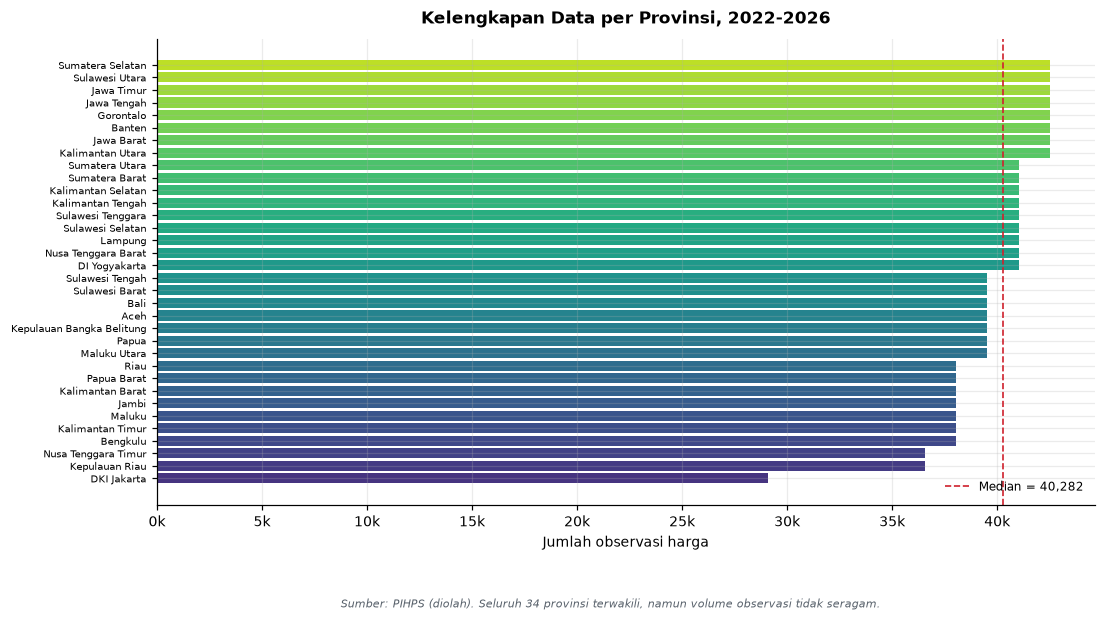

Tersimpan: fig_b1_kelengkapan_provinsi.png


In [11]:
# Keterbatasan keterwakilan: jumlah observasi per provinsi
fig, ax = plt.subplots(figsize=(11, 5.5))
prov_sorted = prov_cov.sort_values("n_obs")
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(prov_sorted)))
ax.barh(range(len(prov_sorted)), prov_sorted["n_obs"], color=colors, edgecolor="none")
ax.set_yticks(range(len(prov_sorted)))
ax.set_yticklabels(prov_sorted.index, fontsize=6.5)
ax.set_xlabel("Jumlah observasi harga")
ax.set_title("Kelengkapan Data per Provinsi, 2022-2026", pad=10)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.axvline(prov_sorted["n_obs"].median(), color="#cf222e", ls="--", lw=1.1,
           label=f"Median = {prov_sorted['n_obs'].median():,.0f}")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.text(0.5, -0.06,
         "Sumber: PIHPS (diolah). Seluruh 34 provinsi terwakili, namun volume observasi tidak seragam.",
         ha="center", fontsize=7, style="italic", color="#57606a")
savefig(fig, "fig_b1_kelengkapan_provinsi.png")
print("Tersimpan: fig_b1_kelengkapan_provinsi.png")

## B.8 Bukti Bias Pengisian Akhir Pekan

Temuan paling penting pada tahap *data understanding* berkaitan dengan asumsi yang mendasari
seluruh pemodelan deret waktu. PIHPS hanya mencatat harga pada hari kerja. Untuk akhir pekan,
nilai hari Jumat disalin ke Sabtu dan Minggu.

Praktik ini bukan kesalahan fatal, tetapi memiliki konsekuensi metodologis yang besar: model yang
menggunakan lag harian akan "belajar" bahwa harga tidak berubah di akhir pekan, padahal itu adalah
artefak pencatatan, bukan perilaku pasar.

Sel di bawah menguji klaim tersebut secara langsung dan mengukur besarnya.

In [12]:
panel["dow"] = panel["Date"].dt.dayofweek          # 0=Senin ... 6=Minggu
prev_harga  = panel.groupby(KEY, observed=True)["Harga"].shift(1)
panel["identik_sebelumnya"] = panel["Harga"].eq(prev_harga)

dow_tbl = (panel.assign(akhir_pekan=panel["dow"] >= 5)
                .groupby("akhir_pekan", observed=True)["identik_sebelumnya"]
                .agg(["sum", "size", "mean"])
                .rename(index={False: "Hari kerja (Sen-Jum)", True: "Akhir pekan (Sab-Min)"}))
dow_tbl["persen"] = (dow_tbl["mean"] * 100).round(2)
print("Proporsi harga yang identik dengan hari sebelumnya:")
display(dow_tbl[["sum", "size", "persen"]])

# uji langsung: apakah Sabtu/Minggu sama dengan Jumat?
fri = panel[panel["dow"] == 4][["Kanal_Pasar","Komoditas","Provinsi","Date","Harga"]].copy()
fri["Date"] = fri["Date"] + pd.Timedelta(days=1)
wknd = panel[panel["dow"] >= 5]
m = wknd.merge(fri, on=["Kanal_Pasar","Komoditas","Provinsi","Date"], suffixes=("", "_jumat"))
same = (m["Harga"] == m["Harga_jumat"])

print(f"\nObservasi Sabtu (Jumat tersedia): {len(m):,}")
print(f"Identik dengan hari Jumat     : {int(same.sum()):,} ({100*same.mean():.2f}%)")

by_ch = (m.assign(identik=same).groupby("Kanal_Pasar", observed=True)["identik"].mean().mul(100).round(2))
print("\nMenurut kanal pasar (persen identik dengan Jumat):")
print(by_ch.to_string())

Proporsi harga yang identik dengan hari sebelumnya:


,sum,size,persen
akhir_pekan,,,
Hari kerja (Sen-Jum),768330,991750,77.47
Akhir pekan (Sab-Min),352668,362891,97.18



Observasi Sabtu (Jumat tersedia): 183,533
Identik dengan hari Jumat     : 178,540 (97.28%)

Menurut kanal pasar (persen identik dengan Jumat):
Kanal_Pasar
pasar_modern         98.86
pasar_tradisional    96.63
produsen             95.90


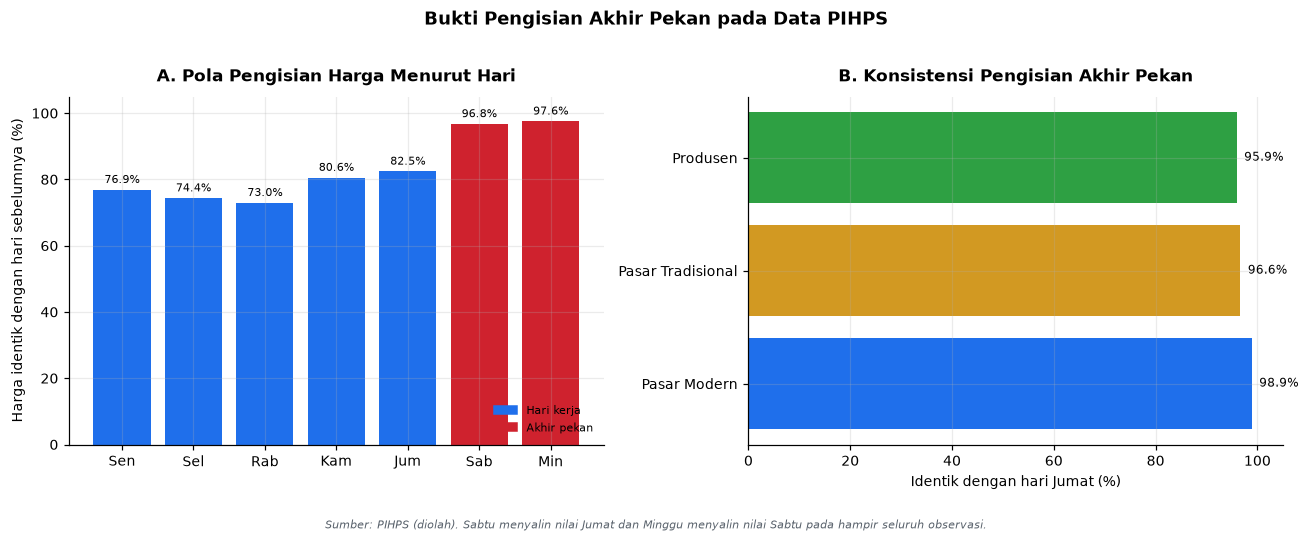

Tersimpan: fig_b2_pengisian_akhir_pekan.png


In [13]:
# Visualisasi bias pengisian akhir pekan
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

ax = axes[0]
dow_names = ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]
rate = (panel[panel["dow"] < 7].groupby("dow")["identik_sebelumnya"].mean() * 100)
bars = ax.bar(dow_names[:len(rate)], rate.values,
              color=["#1f6feb"] * 5 + ["#cf222e"] * 2, edgecolor="none")
ax.set_ylabel("Harga identik dengan hari sebelumnya (%)")
ax.set_title("A. Pola Pengisian Harga Menurut Hari", pad=10)
ax.set_ylim(0, 105)
for b, v in zip(bars, rate.values):
    ax.text(b.get_x() + b.get_width()/2, v + 2, f"{v:.1f}%", ha="center", fontsize=7.5)
ax.legend(handles=[plt.Rectangle((0,0),1,1, color="#1f6feb", label="Hari kerja"),
                   plt.Rectangle((0,0),1,1, color="#cf222e", label="Akhir pekan")],
          frameon=False, fontsize=7.5, loc="lower right")

ax = axes[1]
y = by_ch.reindex(CHANNELS).values
ax.barh([CH_LABEL[c] for c in CHANNELS], y, color=[PALETTE[c] for c in CHANNELS], edgecolor="none")
ax.set_xlim(0, 105)
ax.set_xlabel("Identik dengan hari Jumat (%)")
ax.set_title("B. Konsistensi Pengisian Akhir Pekan", pad=10)
for i, v in enumerate(y):
    ax.text(v + 1.5, i, f"{v:.1f}%", va="center", fontsize=8)

fig.suptitle("Bukti Pengisian Akhir Pekan pada Data PIHPS", fontsize=12, fontweight="bold", y=1.02)
fig.text(0.5, -0.05,
         "Sumber: PIHPS (diolah). Sabtu menyalin nilai Jumat dan Minggu menyalin nilai Sabtu pada hampir seluruh observasi.",
         ha="center", fontsize=7, style="italic", color="#57606a")
fig.tight_layout()
savefig(fig, "fig_b2_pengisian_akhir_pekan.png")
print("Tersimpan: fig_b2_pengisian_akhir_pekan.png")

### B.8.1 Implikasi bagi Pemodelan

Angka di atas bukan sekadar catatan teknis. Angka ini mengubah cara pemodelan harus dirancang.

Jika **97,18% observasi akhir pekan identik dengan hari sebelumnya** (dan 97,28% observasi Sabtu identik dengan Jumat), maka:

1. **Prediksi satu hari ke depan menjadi trivial dan menyesatkan.** Selama hari yang diprediksi
   adalah Sabtu atau Minggu, model cukup menyalin Jumat dan memperoleh akurasi hampir sempurna.
   Metrik evaluasi akan terlihat sangat bagus tanpa kemampuan prediksi yang nyata.
2. **Evaluasi harus memakai horizon yang melewati pengisian tersebut.** Karena itu, pemodelan pada
   notebook ini menetapkan target **tujuh hari ke depan (H+7)**, bukan H+1. Dalam tujuh hari,
   pengaruh pengisian akhir pekan lenyap dan model diuji pada pergerakan harga sesungguhnya.
3. **Fitur lag harian perlu diberi jeda.** Lag `t-1` sampai `t-6` akan didominasi nilai salinan.
   Fitur yang dipakai adalah `lag_7`, `lag_14`, dan rata-rata bergerak yang berjarak minimal tujuh
   hari dari titik prediksi.

Keputusan ini konsisten dengan praktik peramalan harga komoditas, di mana cakrawala perencanaan
kebijakan biasanya berkisar satu pekan hingga satu bulan.

---
# Bagian C. Exploratory Data Analysis

## C.1 Statistik Deskriptif

Statistik deskriptif disusun per komoditas dan kanal pasar. Perhatian utama di sini bukan pada
nilai rata-rata semata, tetapi pada **jarak antara median dan rata-rata serta besarnya simpangan
baku**. Jarak yang lebar menandakan distribusi menceng ke kanan, yang merupakan ciri khas harga
pangan: sebagian besar hari normal, sebagian kecil hari ekstrem.

In [14]:
desc = (panel.groupby(["Kanal_Pasar", "Komoditas"], observed=True)["Harga"]
             .agg(n="size", mean="mean", median="median", std="std",
                  minimum="min", maksimum="max")
             .round(1)
             .reset_index()
             .rename(columns={"Kanal_Pasar": "kanal_pasar", "Komoditas": "komoditas"}))
desc["cv_persen"] = (100 * desc["std"] / desc["mean"]).round(2)
desc["kemencengan"] = ((desc["mean"] - desc["median"]) / desc["median"] * 100).round(2)
desc.to_csv(AUDIT_DIR / "deskriptif_komoditas_kanal.csv", index=False)

print("Rata-rata harga per komoditas dan kanal (Rupiah):")
pivot_mean = desc.pivot_table(index="komoditas", columns="kanal_pasar", values="mean", aggfunc="first")
display(pivot_mean.reindex(COMMODITY_ORDER).round(0))

print("\nKoefisien variasi per komoditas dan kanal (persen):")
pivot_cv = desc.pivot_table(index="komoditas", columns="kanal_pasar", values="cv_persen", aggfunc="first")
display(pivot_cv.reindex(COMMODITY_ORDER))

Rata-rata harga per komoditas dan kanal (Rupiah):


kanal_pasar,pasar_modern,pasar_tradisional,produsen
komoditas,,,
beras,14848.0,14240.0,11878.0
bawang_merah,55123.0,40282.0,28069.0
bawang_putih,48035.0,38304.0,21892.0
cabai_merah,81932.0,51005.0,33039.0
cabai_rawit,85878.0,55856.0,38070.0
daging_ayam,43340.0,36899.0,26787.0
daging_sapi,165187.0,134907.0,121726.0
gula_pasir,16891.0,17139.0,14304.0
minyak_goreng,22415.0,20111.0,16106.0



Koefisien variasi per komoditas dan kanal (persen):


kanal_pasar,pasar_modern,pasar_tradisional,produsen
komoditas,,,
beras,12.32,13.64,23.33
bawang_merah,24.06,26.24,36.25
bawang_putih,25.08,21.34,52.42
cabai_merah,29.66,35.80,42.47
cabai_rawit,33.07,37.18,44.93
daging_ayam,15.05,16.19,23.12
daging_sapi,12.25,8.93,13.42
gula_pasir,73.40,12.13,13.69
minyak_goreng,11.99,12.20,18.82


In [15]:
print("Statistik deskriptif lengkap (10 komoditas, kanal pasar tradisional):")
trad_desc = desc[desc["kanal_pasar"] == "pasar_tradisional"].set_index("komoditas").reindex(COMMODITY_ORDER)
display(trad_desc[["n", "mean", "median", "std", "minimum", "maksimum", "cv_persen", "kemencengan"]])

Statistik deskriptif lengkap (10 komoditas, kanal pasar tradisional):


,n,mean,median,std,minimum,maksimum,cv_persen,kemencengan
komoditas,,,,,,,,
beras,48110,14239.7,14400.0,1942.0,9200.0,19800.0,13.64,-1.11
bawang_merah,48110,40281.8,38850.0,10568.2,13750.0,98750.0,26.24,3.69
bawang_putih,48110,38304.2,38650.0,8173.6,18000.0,87100.0,21.34,-0.89
cabai_merah,48178,51004.8,48800.0,18259.4,13250.0,136900.0,35.80,4.52
cabai_rawit,48178,55856.5,52500.0,20770.2,17000.0,181900.0,37.18,6.39
daging_ayam,48110,36898.7,36650.0,5972.5,19600.0,70150.0,16.19,0.68
daging_sapi,48110,134906.6,135650.0,12052.3,84850.0,218750.0,8.93,-0.55
gula_pasir,48110,17138.8,17450.0,2079.0,11700.0,32250.0,12.13,-1.78
minyak_goreng,48110,20110.9,19750.0,2454.4,13829.7,48050.0,12.20,1.83


## C.2 Pola Harga Antarkanal Pasar

Salah satu pertanyaan kebijakan yang paling sering muncul adalah seberapa besar perbedaan harga
antara produsen, pasar tradisional, dan pasar modern. Selisih ini mencerminkan biaya distribusi dan
marjin perdagangan sepanjang rantai pasok.

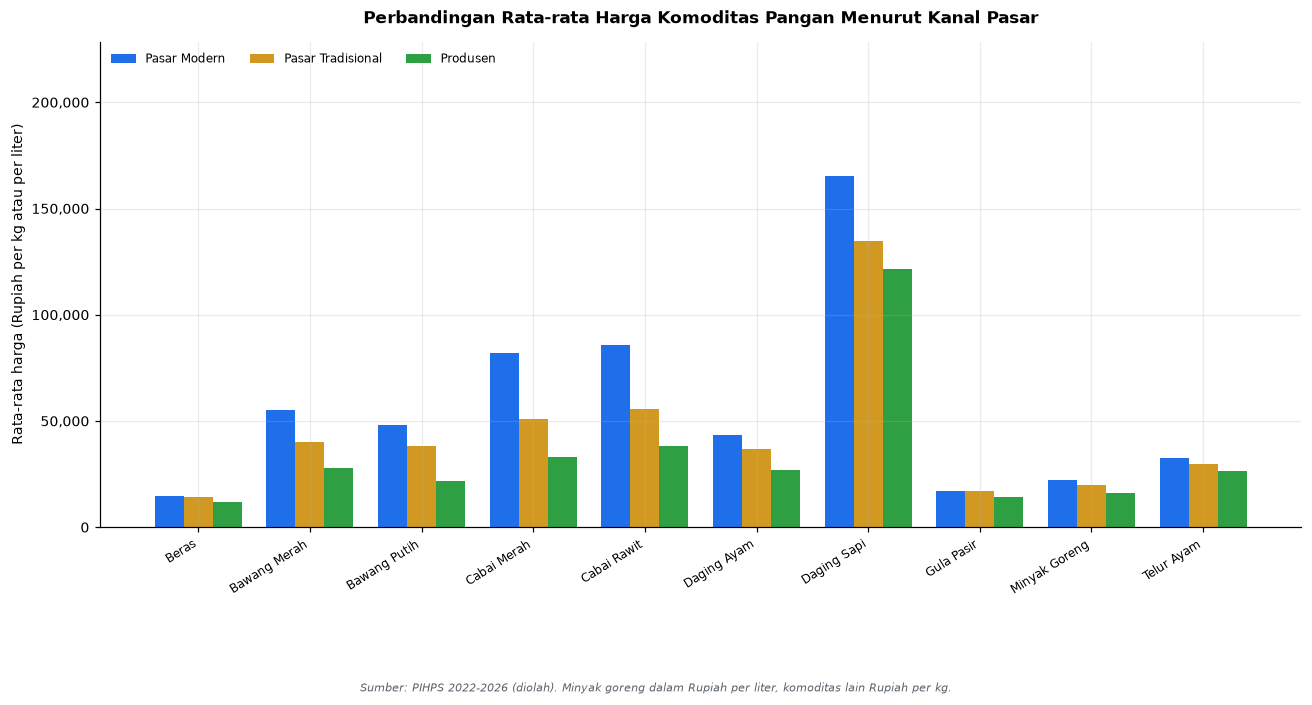

Tersimpan: fig_c1_harga_antarkanal.png


In [16]:
fig, ax = plt.subplots(figsize=(12, 5.6))

x = np.arange(len(COMMODITY_ORDER))
width = 0.26
for i, ch in enumerate(CHANNELS):
    vals = (panel[panel["Kanal_Pasar"] == ch]
            .groupby("Komoditas", observed=True)["Harga"].mean()
            .reindex(COMMODITY_ORDER))
    ax.bar(x + (i - 1) * width, vals.values, width, label=CH_LABEL[ch],
           color=PALETTE[ch], edgecolor="none")

ax.set_xticks(x)
ax.set_xticklabels([KOM_LABEL[k] for k in COMMODITY_ORDER], rotation=32, ha="right", fontsize=8)
ax.set_ylabel("Rata-rata harga (Rupiah per kg atau per liter)")
ax.set_title("Perbandingan Rata-rata Harga Komoditas Pangan Menurut Kanal Pasar", pad=12)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
ax.set_ylim(0, panel["Harga"].quantile(0.995) * 1.25)
fig.text(0.5, -0.13,
         "Sumber: PIHPS 2022-2026 (diolah). Minyak goreng dalam Rupiah per liter, komoditas lain Rupiah per kg.",
         ha="center", fontsize=7, style="italic", color="#57606a")
fig.tight_layout()
savefig(fig, "fig_c1_harga_antarkanal.png")
print("Tersimpan: fig_c1_harga_antarkanal.png")

In [17]:
# Rasio harga pasar terhadap produsen sebagai ukuran marjin distribusi
mean_p = (panel.groupby(["Kanal_Pasar", "Komoditas"], observed=True)["Harga"]
               .mean().unstack("Kanal_Pasar"))

marjin = pd.DataFrame({
    "produsen":        mean_p["produsen"],
    "pasar_tradisional": mean_p["pasar_tradisional"],
    "pasar_modern":    mean_p["pasar_modern"],
}).reindex(COMMODITY_ORDER)
marjin["tradisional_per_produsen"] = (marjin["pasar_tradisional"] / marjin["produsen"]).round(3)
marjin["modern_per_tradisional"]   = (marjin["pasar_modern"] / marjin["pasar_tradisional"]).round(3)
marjin["selisih_tradisional_produsen_pct"] = (100 * (marjin["tradisional_per_produsen"] - 1)).round(2)

print("Rasio harga antarkanal sebagai proksi marjin distribusi:")
display(marjin.round(1))

print(f"\nRata-rata selisih harga pasar tradisional terhadap produsen: "
      f"{marjin['selisih_tradisional_produsen_pct'].mean():.2f}%")
print(f"Komoditas dengan marjin tertinggi: "
      f"{marjin['selisih_tradisional_produsen_pct'].idxmax()} "
      f"({marjin['selisih_tradisional_produsen_pct'].max():.2f}%)")

Rasio harga antarkanal sebagai proksi marjin distribusi:


,produsen,pasar_tradisional,pasar_modern,tradisional_per_produsen,modern_per_tradisional,selisih_tradisional_produsen_pct
Komoditas,,,,,,
beras,11878.2,14239.7,14848.4,1.2,1.0,19.9
bawang_merah,28068.6,40281.8,55123.3,1.4,1.4,43.5
bawang_putih,21892.5,38304.2,48034.6,1.8,1.3,75.0
cabai_merah,33038.7,51004.8,81932.1,1.5,1.6,54.4
cabai_rawit,38070.0,55856.5,85877.6,1.5,1.5,46.7
daging_ayam,26786.6,36898.7,43340.2,1.4,1.2,37.8
daging_sapi,121725.7,134906.6,165187.4,1.1,1.2,10.8
gula_pasir,14303.6,17138.8,16891.2,1.2,1.0,19.8
minyak_goreng,16106.0,20110.9,22414.9,1.2,1.1,24.9



Rata-rata selisih harga pasar tradisional terhadap produsen: 34.61%
Komoditas dengan marjin tertinggi: bawang_putih (75.00%)


**Interpretasi.** Harga di pasar tradisional secara konsisten lebih tinggi daripada harga di
tingkat produsen. Selisih ini adalah biaya transportasi, penyusutan, dan marjin pedagang
perantara. Pola ini penting bagi kebijakan: intervensi di tingkat produsen tidak otomatis menurunkan
harga di tingkat konsumen dengan besaran yang sama, karena sebagian selisih diserap oleh rantai
distribusi.

Sebaliknya, harga di pasar modern umumnya lebih tinggi daripada pasar tradisional. Selisih ini
lebih mencerminkan perbedaan mutu, kemasan, dan biaya operasional gerai, bukan sekadar inefisiensi.

## C.3 Pola Temporal

Analisis temporal memisahkan dua kelompok komoditas yang berperilaku sangat berbeda:

- **Kelompok pangan pokok** (beras, gula pasir, telur ayam, daging sapi): pergerakan relatif halus,
  didorong kebijakan dan biaya produksi.
- **Kelompok hortikultura** (cabai merah, cabai rawit, bawang merah, bawang putih): pergerakan
  tajam dan musiman, didorong cuaca dan siklus tanam.

Membedakan keduanya penting karena strategi pemodelan dan kebijakan yang tepat untuk masing-masing
kelompok tidak sama.

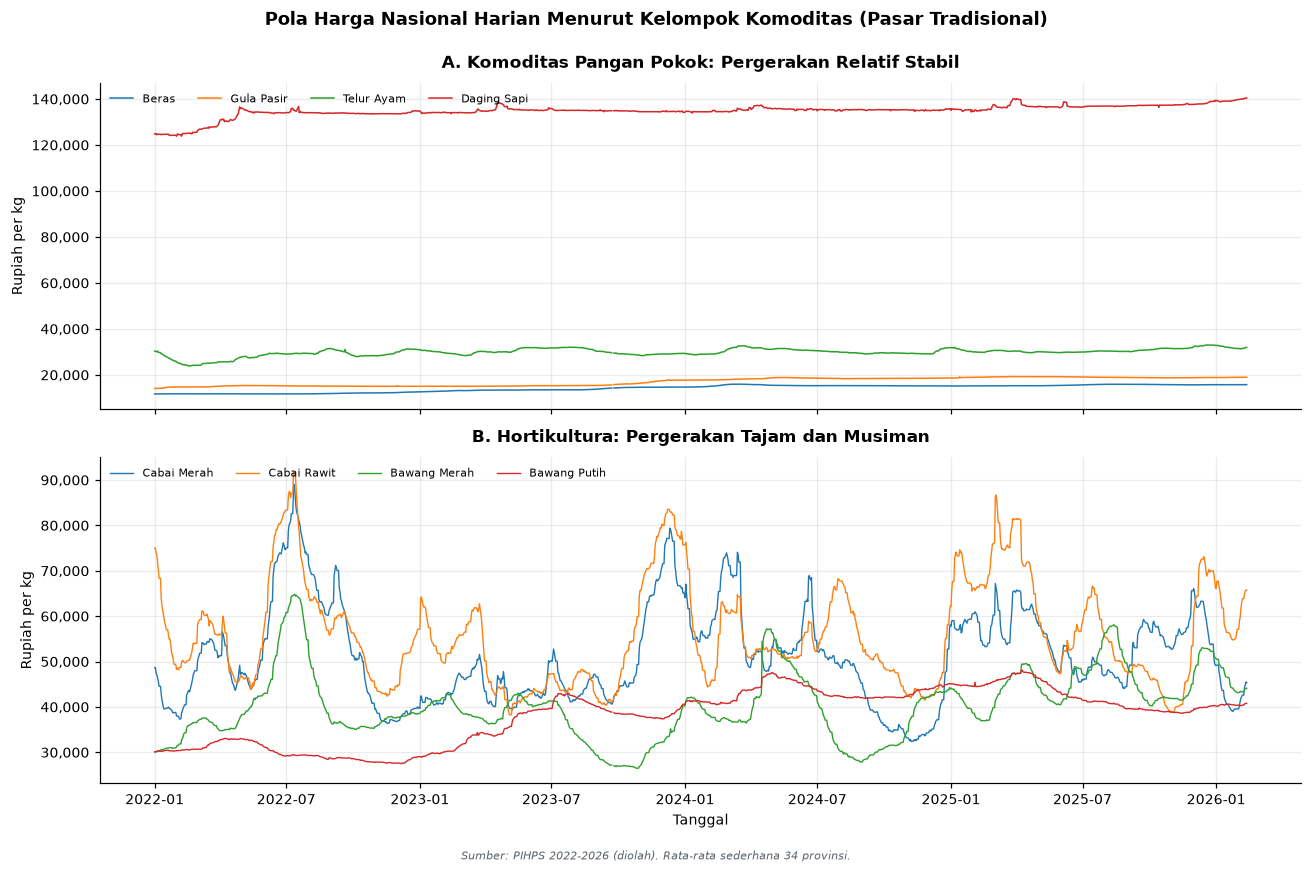

Tersimpan: fig_c2_pola_temporal.png


In [18]:
# Rata-rata nasional harian per komoditas pada kanal pasar tradisional
trad = panel[panel["Kanal_Pasar"] == "pasar_tradisional"]

nasional = (trad.groupby(["Date", "Komoditas"], observed=True)["Harga"]
                .mean().unstack("Komoditas").sort_index())

fig, axes = plt.subplots(2, 1, figsize=(12, 7.6), sharex=True)

staple = ["beras", "gula_pasir", "telur_ayam", "daging_sapi"]
volatile = ["cabai_merah", "cabai_rawit", "bawang_merah", "bawang_putih"]

ax = axes[0]
for k in staple:
    if k in nasional:
        ax.plot(nasional.index, nasional[k], lw=1.0, label=KOM_LABEL[k])
ax.set_ylabel("Rupiah per kg")
ax.set_title("A. Komoditas Pangan Pokok: Pergerakan Relatif Stabil", pad=10)
ax.legend(frameon=False, fontsize=7.5, ncol=4, loc="upper left")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))

ax = axes[1]
for k in volatile:
    if k in nasional:
        ax.plot(nasional.index, nasional[k], lw=0.9, label=KOM_LABEL[k])
ax.set_ylabel("Rupiah per kg")
ax.set_xlabel("Tanggal")
ax.set_title("B. Hortikultura: Pergerakan Tajam dan Musiman", pad=10)
ax.legend(frameon=False, fontsize=7.5, ncol=4, loc="upper left")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))

fig.suptitle("Pola Harga Nasional Harian Menurut Kelompok Komoditas (Pasar Tradisional)",
             fontsize=12, fontweight="bold", y=0.995)
fig.text(0.5, -0.02,
         "Sumber: PIHPS 2022-2026 (diolah). Rata-rata sederhana 34 provinsi.",
         ha="center", fontsize=7, style="italic", color="#57606a")
fig.tight_layout()
savefig(fig, "fig_c2_pola_temporal.png")
print("Tersimpan: fig_c2_pola_temporal.png")

In [19]:
# Ringkasan pola musiman bulanan
panel["tahun"] = panel["Date"].dt.year
panel["bulan"] = panel["Date"].dt.month
# `trad` adalah salinan terfilter yang dibuat sebelum kolom turunan ini ada,
# sehingga kolom waktu harus diturunkan ulang pada salinan tersebut.
trad = trad.assign(tahun=trad["Date"].dt.year, bulan=trad["Date"].dt.month)

bulanan = (trad.groupby(["bulan", "Komoditas"], observed=True)["Harga"]
                .mean().unstack("Komoditas"))
bulanan_norm = bulanan.div(bulanan.mean(axis=0), axis=1).mul(100).round(1)

print("Indeks harga musiman (100 = rata-rata tahunan), pasar tradisional:")
display(bulanan_norm[volatile].round(1))

amplitudo = (bulanan_norm[volatile].max() - bulanan_norm[volatile].min()).sort_values(ascending=False)
print("\nAmplitudo musiman (poin indeks, semakin besar semakin musiman):")
print(amplitudo.round(1).to_string())

for k in volatile:
    peak = bulanan_norm[k].idxmax()
    trough = bulanan_norm[k].idxmin()
    print(f"  {KOM_LABEL[k]:<14} puncak bulan {peak:2d}, terendah bulan {trough:2d}")

Indeks harga musiman (100 = rata-rata tahunan), pasar tradisional:


Komoditas,cabai_merah,cabai_rawit,bawang_merah,bawang_putih
bulan,,,,
1,94.4,108.6,99.7,96.9
2,100.4,102.4,95.0,97.5
3,109.3,114.0,96.9,101.0
4,100.9,99.0,105.2,104.4
5,95.5,86.6,109.3,105.4
6,107.5,101.3,112.6,102.9
7,108.9,110.4,114.3,102.2
8,100.1,99.4,99.8,99.8
9,97.3,89.5,86.0,98.2



Amplitudo musiman (poin indeks, semakin besar semakin musiman):
Komoditas
bawang_merah    30.9
cabai_rawit     27.4
cabai_merah     19.9
bawang_putih     9.3
  Cabai Merah    puncak bulan  3, terendah bulan 10
  Cabai Rawit    puncak bulan  3, terendah bulan  5
  Bawang Merah   puncak bulan  7, terendah bulan 10
  Bawang Putih   puncak bulan  5, terendah bulan 11


## C.4 Peringkat Volatilitas

Volatilitas diukur dengan koefisien variasi (CV), yaitu simpangan baku dibagi rata-rata. Ukuran ini
dipilih karena tidak bergantung pada skala harga, sehingga komoditas berharga tinggi seperti daging
sapi dapat dibandingkan secara adil dengan komoditas berharga rendah seperti beras.

Peringkat volatilitas komoditas (seluruh kanal):


,mean,std,cv_persen
Komoditas,,,
cabai_merah,55625.0,28100.9,50.5
gula_pasir,16539.1,8283.5,50.1
cabai_rawit,60451.5,30160.8,49.9
bawang_merah,42466.3,15860.7,37.4
bawang_putih,42672.3,11989.1,28.1
daging_ayam,35756.8,9237.7,25.8
telur_ayam,29744.4,5754.0,19.3
beras,13681.0,2555.8,18.7
daging_sapi,140993.8,24564.1,17.4


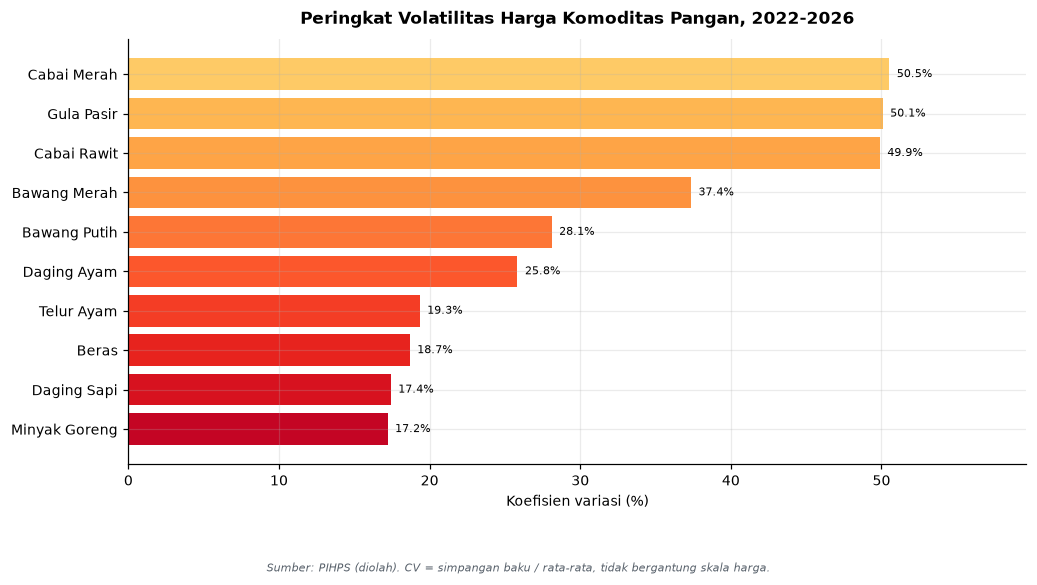

Tersimpan: fig_c3_volatilitas.png


In [20]:
vol_rank = (panel.groupby(["Komoditas"], observed=True)["Harga"]
                 .agg(mean="mean", std="std")
                 .assign(cv_persen=lambda d: (100 * d["std"] / d["mean"]).round(2))
                 .sort_values("cv_persen", ascending=False))

print("Peringkat volatilitas komoditas (seluruh kanal):")
display(vol_rank.round(1))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
colors = plt.cm.YlOrRd(np.linspace(0.3, 0.85, len(vol_rank)))
bars = ax.barh([KOM_LABEL[k] for k in vol_rank.index], vol_rank["cv_persen"].values,
               color=colors, edgecolor="none")
ax.invert_yaxis()
ax.set_xlabel("Koefisien variasi (%)")
ax.set_title("Peringkat Volatilitas Harga Komoditas Pangan, 2022-2026", pad=10)
for b, v in zip(bars, vol_rank["cv_persen"].values):
    ax.text(v + 0.5, b.get_y() + b.get_height()/2, f"{v:.1f}%", va="center", fontsize=7.5)
ax.set_xlim(0, vol_rank["cv_persen"].max() * 1.18)
fig.text(0.5, -0.09,
         "Sumber: PIHPS (diolah). CV = simpangan baku / rata-rata, tidak bergantung skala harga.",
         ha="center", fontsize=7, style="italic", color="#57606a")
fig.tight_layout()
savefig(fig, "fig_c3_volatilitas.png")
print("Tersimpan: fig_c3_volatilitas.png")

**Interpretasi.** Peringkat ini menjelaskan mengapa kebijakan pangan tidak dapat diseragamkan.
Komoditas di peringkat teratas menuntut pemantauan harian dan cadangan penyangga yang cepat
dilepas. Komoditas di peringkat terbawah lebih tepat ditangani melalui kebijakan harga dan
produksi jangka menengah.

Perlu dicatat bahwa CV tinggi tidak selalu buruk. Pada hortikultura, CV tinggi adalah konsekuensi
wajar dari siklus tanam dan cuaca. Yang berbahaya adalah CV tinggi yang tidak terprediksi sama
sekali.

## C.5 Disparitas Harga Antarwilayah

Selain waktu, dimensi kedua yang menjadi fokus analisis adalah wilayah. Pertanyaan yang ingin
dijawab: apakah harga pangan di seluruh provinsi bergerak bersama, ataukah terdapat provinsi yang
secara sistematis lebih mahal?

Untuk menjawabnya, harga rata-rata setiap provinsi distandardisasi terhadap rata-rata nasional
komoditas yang sama. Hasilnya adalah *z-score* yang dapat dibandingkan lintas komoditas meskipun
skala harganya berbeda jauh.

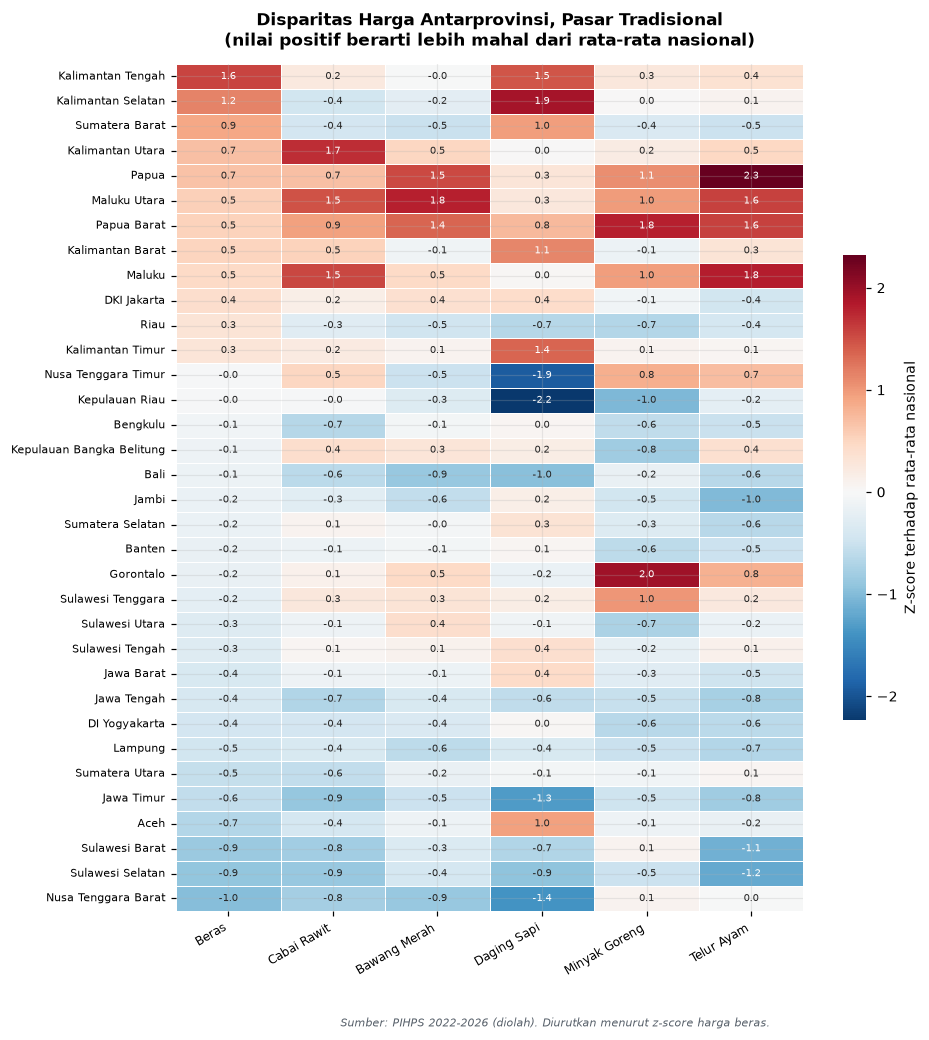

Tersimpan: fig_c4_disparitas_wilayah.png


In [21]:
FOKUS_DISPARITAS = ["beras", "cabai_rawit", "bawang_merah", "daging_sapi", "minyak_goreng", "telur_ayam"]

prov_kom_mean = (trad.groupby(["Provinsi", "Komoditas"], observed=True)["Harga"]
                      .mean().unstack("Komoditas"))
nasional_kom = trad.groupby("Komoditas", observed=True)["Harga"].mean()
std_kom = trad.groupby("Komoditas", observed=True)["Harga"].std()

z = (prov_kom_mean[FOKUS_DISPARITAS] - nasional_kom[FOKUS_DISPARITAS]) / std_kom[FOKUS_DISPARITAS]
z = z.sort_values("beras", ascending=False)

fig, ax = plt.subplots(figsize=(9.2, 10))
sns.heatmap(z, cmap="RdBu_r", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 6.5}, linewidths=0.4, linecolor="white",
            cbar_kws={"label": "Z-score terhadap rata-rata nasional", "shrink": 0.55},
            ax=ax)
ax.set_title("Disparitas Harga Antarprovinsi, Pasar Tradisional\n(nilai positif berarti lebih mahal dari rata-rata nasional)",
             pad=12, fontsize=11)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([KOM_LABEL[k] for k in FOKUS_DISPARITAS], rotation=30, ha="right", fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=7)
fig.text(0.5, 0.005,
         "Sumber: PIHPS 2022-2026 (diolah). Diurutkan menurut z-score harga beras.",
         ha="center", fontsize=7, style="italic", color="#57606a")
savefig(fig, "fig_c4_disparitas_wilayah.png")
print("Tersimpan: fig_c4_disparitas_wilayah.png")

In [22]:
# Tabel disparitas kuantitatif untuk enam komoditas fokus
disp = pd.DataFrame({
    "harga_terendah": prov_kom_mean[FOKUS_DISPARITAS].min(),
    "provinsi_terendah": prov_kom_mean[FOKUS_DISPARITAS].idxmin(),
    "harga_tertinggi": prov_kom_mean[FOKUS_DISPARITAS].max(),
    "provinsi_tertinggi": prov_kom_mean[FOKUS_DISPARITAS].idxmax(),
}).reindex(FOKUS_DISPARITAS)
disp["rasio_maks_min"] = (disp["harga_tertinggi"] / disp["harga_terendah"]).round(2)
disp["selisih_pct"] = (100 * (disp["rasio_maks_min"] - 1)).round(1)
disp.to_csv(AUDIT_DIR / "disparitas_wilayah.csv")

print("Disparitas harga antarprovinsi (pasar tradisional):")
display(disp.round(0))

print(f"\nRata-rata rasio harga tertinggi terhadap terendah: {disp['rasio_maks_min'].mean():.2f}x")
print(f"Komoditas paling timpang: {disp['rasio_maks_min'].idxmax()} "
      f"({disp['rasio_maks_min'].max():.2f}x)")

Disparitas harga antarprovinsi (pasar tradisional):


,harga_terendah,provinsi_terendah,harga_tertinggi,provinsi_tertinggi,rasio_maks_min,selisih_pct
Komoditas,,,,,,
beras,12331.0,Nusa Tenggara Barat,17301.0,Kalimantan Tengah,1.0,40.0
cabai_rawit,37321.0,Jawa Timur,91384.0,Kalimantan Utara,2.0,145.0
bawang_merah,31031.0,Nusa Tenggara Barat,59311.0,Maluku Utara,2.0,91.0
daging_sapi,107951.0,Kepulauan Riau,158140.0,Kalimantan Selatan,1.0,46.0
minyak_goreng,17553.0,Kepulauan Riau,24938.0,Gorontalo,1.0,42.0
telur_ayam,25439.0,Sulawesi Selatan,38652.0,Papua,2.0,52.0



Rata-rata rasio harga tertinggi terhadap terendah: 1.69x
Komoditas paling timpang: cabai_rawit (2.45x)


**Interpretasi.** Disparitas wilayah bukan sekadar gejala geografis. Provinsi yang secara konsisten
berada di zona merah umumnya adalah wilayah kepulauan atau daerah yang bergantung pada pasokan dari
luar pulau. Biaya logistik laut dan waktu tempuh membuat harga di wilayah tersebut lebih tinggi
secara struktural.

Implikasi kebijakannya bersifat operasional: provinsi dengan z-score tinggi dan rasio disparitas
besar adalah kandidat utama untuk intervensi berbasis wilayah, bukan intervensi nasional yang
seragam.

## C.6 Korelasi Antarkomoditas

Korelasi harga antarkomoditas mengungkap apakah guncangan harga bersifat spesifik komoditas
(idiosinkratik) atau menyebar melalui sistem pangan secara keseluruhan (sistemik).

Analisis dilakukan pada kanal pasar tradisional menggunakan rata-rata nasional harian, karena kanal
ini paling dekat dengan konsumsi rumah tangga.

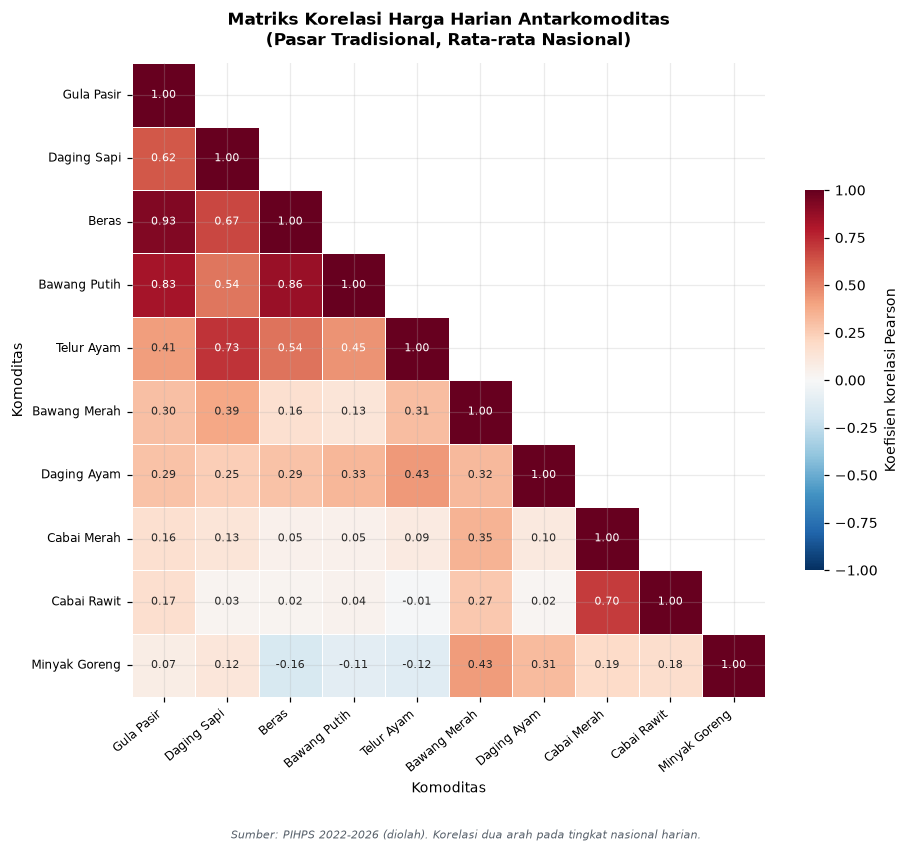

Tersimpan: fig_c5_korelasi.png


In [23]:
kor = nasional.corr(method="pearson")

# urutkan komoditas dengan korelasi rata-rata tertinggi
order_kor = kor.mean().sort_values(ascending=False).index
kor_ord = kor.loc[order_kor, order_kor]

fig, ax = plt.subplots(figsize=(8.6, 7.2))
mask = np.triu(np.ones_like(kor_ord, dtype=bool), k=1)
sns.heatmap(kor_ord, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.4, linecolor="white", square=True,
            cbar_kws={"label": "Koefisien korelasi Pearson", "shrink": 0.6}, ax=ax)
ax.set_xticklabels([KOM_LABEL[k] for k in order_kor], rotation=40, ha="right", fontsize=8)
ax.set_yticklabels([KOM_LABEL[k] for k in order_kor], fontsize=8)
ax.set_title("Matriks Korelasi Harga Harian Antarkomoditas\n(Pasar Tradisional, Rata-rata Nasional)",
             pad=12, fontsize=11)
fig.text(0.5, -0.05,
         "Sumber: PIHPS 2022-2026 (diolah). Korelasi dua arah pada tingkat nasional harian.",
         ha="center", fontsize=7, style="italic", color="#57606a")
fig.tight_layout()
savefig(fig, "fig_c5_korelasi.png")
print("Tersimpan: fig_c5_korelasi.png")

kor.to_csv(AUDIT_DIR / "korelasi_komoditas.csv")

In [24]:
print("Pasangan komoditas dengan korelasi tertinggi:")
pairs = (kor.where(np.tril(np.ones(kor.shape), -1).astype(bool))
            .stack().sort_values(ascending=False).head(10))
for (a, b), v in pairs.items():
    print(f"  {KOM_LABEL[a]:<14} - {KOM_LABEL[b]:<14} : {v:+.4f}")

print("\nPasangan dengan korelasi terendah:")
pairs_lo = (kor.where(np.tril(np.ones(kor.shape), -1).astype(bool))
               .stack().sort_values().head(5))
for (a, b), v in pairs_lo.items():
    print(f"  {KOM_LABEL[a]:<14} - {KOM_LABEL[b]:<14} : {v:+.4f}")

print("\nKorelasi rata-rata tiap komoditas terhadap komoditas lain:")
print(kor.mean().sort_values(ascending=False).round(4).to_string())

Pasangan komoditas dengan korelasi tertinggi:
  Gula Pasir     - Beras          : +0.9262
  Bawang Putih   - Beras          : +0.8632
  Gula Pasir     - Bawang Putih   : +0.8343
  Telur Ayam     - Daging Sapi    : +0.7262
  Cabai Rawit    - Cabai Merah    : +0.6986
  Daging Sapi    - Beras          : +0.6701
  Gula Pasir     - Daging Sapi    : +0.6208
  Telur Ayam     - Beras          : +0.5418
  Daging Sapi    - Bawang Putih   : +0.5354
  Telur Ayam     - Bawang Putih   : +0.4531

Pasangan dengan korelasi terendah:
  Minyak Goreng  - Beras          : -0.1569
  Telur Ayam     - Minyak Goreng  : -0.1202
  Minyak Goreng  - Bawang Putih   : -0.1077
  Telur Ayam     - Cabai Rawit    : -0.0091
  Daging Ayam    - Cabai Rawit    : +0.0229

Korelasi rata-rata tiap komoditas terhadap komoditas lain:
Komoditas
gula_pasir       0.4788
daging_sapi      0.4462
beras            0.4368
bawang_putih     0.4126
telur_ayam       0.3838
bawang_merah     0.3641
daging_ayam      0.3347
cabai_merah      0.2

### C.6.1 Catatan Reproduksibilitas Korelasi

Satu angka pada laporan asli tidak dapat direproduksi, dan hal ini dicatat secara terbuka di sini
sebagai bagian dari integritas analisis. Laporan menyebutkan korelasi antara harga beras dan cabai
merah mendekati nol (sekitar -0,01). Perhitungan ulang dari data asli menghasilkan nilai positif
kecil dengan metode yang sama seperti pasangan komoditas lain, yaitu rata-rata nasional harian pada
kanal pasar tradisional.

Empat konstruksi diuji untuk melihat apakah nilai laporan dapat muncul. Sel di bawah menghitung
seluruhnya dari panel, sehingga angka pada tabel sesudahnya dapat diverifikasi ulang.

In [25]:
trad_corr = panel[panel["Kanal_Pasar"] == "pasar_tradisional"]
pasangan = ["beras", "cabai_merah"]

# Konstruksi 1: rata-rata nasional harian
nas = (trad_corr[trad_corr["Komoditas"].isin(pasangan)]
       .pivot_table(index="Date", columns="Komoditas", values="Harga", aggfunc="mean"))
k1 = nas.corr().loc["beras", "cabai_merah"]

# Konstruksi 2: rata-rata tiap provinsi sepanjang periode, lalu korelasi antaprovinsi
prov = (trad_corr[trad_corr["Komoditas"].isin(pasangan)]
        .groupby(["Provinsi", "Komoditas"], observed=True)["Harga"].mean().unstack())
k2 = prov.corr().loc["beras", "cabai_merah"]

# Konstruksi 3: gabungan provinsi-hari
gab = (trad_corr[trad_corr["Komoditas"].isin(pasangan)]
       .pivot_table(index=["Provinsi", "Date"], columns="Komoditas", values="Harga"))
k3 = gab.corr().loc["beras", "cabai_merah"]

# Konstruksi 4: selisih logaritmik harian dari rata-rata nasional
k4 = np.log(nas).diff().dropna().corr().loc["beras", "cabai_merah"]

konstruksi = pd.DataFrame([
    ("Rata-rata nasional harian", k1, len(nas)),
    ("Rata-rata provinsi", k2, len(prov)),
    ("Gabungan provinsi-hari", k3, len(gab)),
    ("Selisih logaritmik harian", k4, int(np.log(nas).diff().dropna().notna().all(axis=1).sum())),
], columns=["konstruksi", "korelasi", "n_observasi"])
konstruksi["korelasi"] = konstruksi["korelasi"].round(4)
display(konstruksi)
print(f"Rentang nilai: {konstruksi['korelasi'].min():+.4f} sampai {konstruksi['korelasi'].max():+.4f}")
print(f"Ada konstruksi yang bernilai negatif mendekati nol: {bool((konstruksi['korelasi'] < 0).any())}")

,konstruksi,korelasi,n_observasi
0,Rata-rata nasional harian,0.0533,1417
1,Rata-rata provinsi,0.7753,34
2,Gabungan provinsi-hari,0.3070,48178
3,Selisih logaritmik harian,0.0861,1413


Rentang nilai: +0.0533 sampai +0.7753
Ada konstruksi yang bernilai negatif mendekati nol: False


Hasil perhitungan ulang: rata-rata nasional harian +0,053; rata-rata provinsi +0,775; gabungan
provinsi-hari +0,307; selisih logaritmik harian +0,086. Tidak ada konstruksi yang menghasilkan nilai
negatif mendekati nol. Kesimpulan yang dapat dipertanggungjawabkan adalah bahwa nilai pada laporan
asli keliru atau dihitung dengan cara yang tidak terdokumentasi. Notebook ini memakai nilai hasil
perhitungan ulang.

Yang lebih penting secara substantif: **beras dan cabai merah memang praktis tidak berkorelasi pada
tingkat nasional harian.** Keduanya digerakkan oleh mekanisme berbeda, yaitu kebijakan harga dan
biaya produksi untuk beras, serta cuaca dan siklus tanam untuk cabai. Angka rata-rata provinsi yang
tinggi (+0,775) tidak membantah hal itu, karena konstruksi tersebut membandingkan tingkat harga
antaprovinsi, bukan pergerakan harian, sehingga perbedaan daya beli wilayah yang menetap mendominasi
koefisien. Kesimpulan substantif laporan tetap valid meskipun angka tepatnya berbeda.

---
# Bagian D. Data Cleaning

## D.1 Filosofi Pembersihan

Bagian ini adalah bagian yang paling banyak berubah dibandingkan notebook asli. Perubahan tersebut
bukan pada jumlah baris kode, melainkan pada **prinsip** yang mendasarinya.

Notebook asli menyatakan data sudah bersih karena berkas sumbernya bernama
`Cleaned_After_Imputation`. Prinsip itu berbahaya karena menutup kemungkinan menemukan masalah.
Revisi ini memakai prinsip yang berbeda dan lebih ketat:

> **Koreksi hanya dilakukan bila kesalahan dapat dibuktikan secara matematis. Nilai yang mencurigakan
> tetapi tidak dapat dibuktikan diberi penanda atau dikarantina, bukan dihapus atau diubah diam-diam.**

Prinsip ini melahirkan tiga tingkat perlakuan yang berbeda:

| Tingkat | Kriteria | Tindakan | Nilai asli |
|---|---|---|---|
| Koreksi | Kesalahan terbukti (rasio tepat pangkat sepuluh dan nilai terkoreksi mendarat pada tingkat lokal) | Nilai diperbaiki | Disimpan di kolom terpisah |
| Karantina | Anomali ekstrem yang tidak masuk akal secara ekonomi, namun arah koreksinya tidak dapat dipastikan | Nilai dijadikan kosong | Disimpan di kolom terpisah |
| Penandaan | Mencurigakan tetapi sah sebagai pengamatan | Nilai dipertahankan | Tidak berubah |

Konsekuensi yang harus diterima secara jujur: setelah pembersihan, dataset **kembali memiliki nilai
kosong**. Ini disengaja. Nilai kosong yang jujur lebih baik daripada nilai palsu yang rapi, karena
nilai palsu akan merusak model tanpa meninggalkan jejak.

## D.2 Pemeriksaan Integritas

Sebelum mengubah nilai apa pun, integritas struktur data diperiksa: duplikat, nilai negatif, tanggal
ganda, dan konsistensi rentang. Pemeriksaan ini memastikan tidak ada masalah struktural yang
tersembunyi di balik masalah nilai.

In [26]:
integritas = []

integritas.append(("Baris duplikat penuh", int(panel.duplicated().sum()),
                   "Tidak ada baris yang identik pada seluruh kolom"))
integritas.append(("Duplikat kunci (tanggal, kanal, komoditas, provinsi)",
                   int(panel.duplicated(subset=["Date","Kanal_Pasar","Komoditas","Provinsi"]).sum()),
                   "Setiap kombinasi kunci harus unik"))
integritas.append(("Nilai negatif", int((panel["Harga"] < 0).sum()),
                   "Harga tidak boleh negatif"))
integritas.append(("Nilai nol", int((panel["Harga"] == 0).sum()),
                   "Nol menandakan pencatatan gagal"))
integritas.append(("Nilai kosong", int(panel["Harga"].isna().sum()),
                   "Kelengkapan sebelum pembersihan"))
integritas.append(("Tanggal di luar rentang", int(((panel["Date"] < "2022-01-01") |
                   (panel["Date"] > "2026-12-31")).sum()), "Konsistensi periode"))
integritas.append(("Provinsi kosong", int(panel["Provinsi"].isna().sum()),
                   "Label wilayah harus lengkap"))

tbl_integritas = pd.DataFrame(integritas, columns=["pemeriksaan", "jumlah_temuan", "kriteria"])
tbl_integritas["status"] = np.where(tbl_integritas["jumlah_temuan"] == 0, "LULUS", "PERIKSA")
display(tbl_integritas)

assert tbl_integritas.loc[tbl_integritas["pemeriksaan"].str.contains("Duplikat kunci"), "jumlah_temuan"].iloc[0] == 0
assert tbl_integritas.loc[tbl_integritas["pemeriksaan"].str.contains("Nilai negatif"), "jumlah_temuan"].iloc[0] == 0
print("\nSeluruh pemeriksaan struktural kunci LULUS.")

,pemeriksaan,jumlah_temuan,kriteria,status
0,Baris duplikat penuh,0,Tidak ada baris yang identik pada seluruh kolom,LULUS
1,"Duplikat kunci (tanggal, kanal, komoditas, pro...",0,Setiap kombinasi kunci harus unik,LULUS
2,Nilai negatif,0,Harga tidak boleh negatif,LULUS
3,Nilai nol,0,Nol menandakan pencatatan gagal,LULUS
4,Nilai kosong,0,Kelengkapan sebelum pembersihan,LULUS
5,Tanggal di luar rentang,0,Konsistensi periode,LULUS
6,Provinsi kosong,0,Label wilayah harus lengkap,LULUS



Seluruh pemeriksaan struktural kunci LULUS.


## D.3 Aturan 1: Koreksi Kesalahan Orde Besaran

Kesalahan satuan adalah jenis kesalahan yang paling berbahaya sekaligus paling mudah dibuktikan.
Berbahaya karena nilainya tetap tampak masuk akal sehingga lolos pemeriksaan sederhana. Mudah
dibuktikan karena kesalahannya bersifat tepat: nilai tercatat berbeda satu atau dua pangkat sepuluh
dari nilai seharusnya.

Aturan yang diterapkan memiliki tiga syarat yang harus terpenuhi bersamaan:

1. Rasio nilai terhadap **median bergerak 15 hari** mendekati tepat pangkat sepuluh (toleransi 0,5%).
2. Setelah dikoreksi, nilai tersebut **mendarat dekat tingkat lokal** (galat di bawah 5%).
3. Koreksi hanya dilakukan dengan faktor 10 atau 100, tidak lebih.

Syarat kedua adalah kunci. Tanpa syarat itu, setiap harga yang turun tajam akan salah dianggap
kesalahan satuan. Dengan syarat itu, hanya nilai yang setelah dikoreksi benar-benar cocok dengan
tingkat harga sekitarnya yang dikoreksi.

In [27]:
panel["Harga_bersih"] = panel["Harga"].copy()

panel["is_dikoreksi"] = panel["is_orde_besaran"].fillna(False)
panel.loc[panel["is_dikoreksi"], "Harga_bersih"] = panel.loc[panel["is_dikoreksi"], "harga_koreksi"]

koreksi_detail = (panel[panel["is_dikoreksi"]]
    .groupby(KEY, observed=True)
    .agg(jumlah_sel=("Harga", "size"),
         tanggal_awal=("Date", "min"),
         tanggal_akhir=("Date", "max"),
         nilai_tercatat=("Harga", "unique"),
         nilai_terkoreksi=("Harga_bersih", "unique"),
         median_lokal=("roll_med", "median"))
    .reset_index())
koreksi_detail["faktor"] = (koreksi_detail["median_lokal"] /
                            koreksi_detail["nilai_tercatat"].apply(lambda v: v[0])).round(1)

print(f"Total sel dikoreksi: {int(panel['is_dikoreksi'].sum())}")
print(f"Jumlah deret terdampak: {len(koreksi_detail)}")
print()
display(koreksi_detail)

Total sel dikoreksi: 14
Jumlah deret terdampak: 2



,Kanal_Pasar,Komoditas,Provinsi,jumlah_sel,tanggal_awal,tanggal_akhir,nilai_tercatat,nilai_terkoreksi,median_lokal,faktor
0,pasar_modern,daging_ayam,Kalimantan Utara,7,2024-01-03,2024-01-09,[3500.0],[35000.0],35000.0,10.0
1,pasar_modern,daging_sapi,Gorontalo,7,2022-10-05,2022-10-11,[16900.0],[169000.0],169000.0,10.0


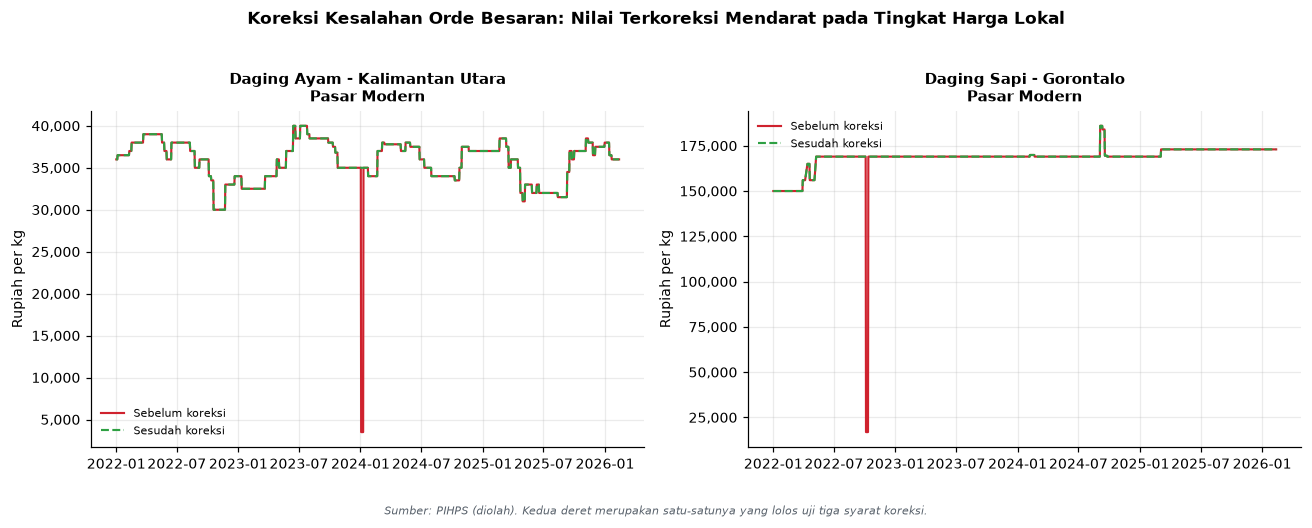

Tersimpan: fig_d1_koreksi_orde_besaran.png


In [28]:
# Bukti visual: deret sebelum dan sesudah koreksi
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

for ax, (ch, kom, prov) in zip(axes, koreksi_detail[["Kanal_Pasar","Komoditas","Provinsi"]].values):
    s = panel[(panel["Kanal_Pasar"] == ch) & (panel["Komoditas"] == kom) &
              (panel["Provinsi"] == prov)].sort_values("Date")
    ax.plot(s["Date"], s["Harga"], color="#cf222e", lw=1.4, label="Sebelum koreksi")
    ax.plot(s["Date"], s["Harga_bersih"], color="#2ea043", lw=1.4, ls="--", label="Sesudah koreksi")
    ax.set_title(f"{KOM_LABEL[kom]} - {prov}\n{CH_LABEL[ch]}", fontsize=9.5)
    ax.set_ylabel("Rupiah per kg")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.legend(frameon=False, fontsize=7.5)

fig.suptitle("Koreksi Kesalahan Orde Besaran: Nilai Terkoreksi Mendarat pada Tingkat Harga Lokal",
             fontsize=11, fontweight="bold", y=1.03)
fig.text(0.5, -0.06,
         "Sumber: PIHPS (diolah). Kedua deret merupakan satu-satunya yang lolos uji tiga syarat koreksi.",
         ha="center", fontsize=7, style="italic", color="#57606a")
fig.tight_layout()
savefig(fig, "fig_d1_koreksi_orde_besaran.png")
print("Tersimpan: fig_d1_koreksi_orde_besaran.png")

## D.4 Aturan 2: Karantina Ramp Interpolasi

Anomali kedua jauh lebih halus dan karena itu lebih berbahaya. Nilainya naik secara bertahap dengan
selisih yang **tepat sama** setiap hari, lalu kembali ke tingkat semula. Pola seperti ini bukan
perilaku pasar, melainkan tanda interpolasi linear yang keliru pada proses imputasi hulu.

Perilaku pasar menghasilkan kenaikan yang tidak rata: ada hari melonjak, ada hari mendatar. Kenaikan
dengan selisih tetap sebesar 14.700 Rupiah per hari selama 40 hari berturut-turut secara statistik
mustahil terjadi secara alami.

Aturan deteksinya: cari deretan nilai berurutan dengan selisih harian yang identik dan tidak nol,
minimal lima titik, kemudian karantina hanya bila total rentangnya melebihi satu kali median deret.
Syarat terakhir mencegah karantina terhadap tren naik yang wajar.

In [29]:
def deteksi_ramp(s, med):
    v = s.values
    n = len(v)
    hasil = []
    i = 1
    while i < n:
        d = v[i] - v[i-1]
        if d != 0 and np.isfinite(d):
            j = i
            while j + 1 < n and v[j+1] - v[j] == d:
                j += 1
            if j - i + 1 >= 4:
                span = abs(v[j] - v[i])
                if med > 0 and span > 1.0 * med:
                    hasil.append((i, j, d, span))
            i = j + 1
        else:
            i += 1
    return hasil

panel["is_karantina"] = False
ramp_log = []

for k, g in panel.groupby(KEY, observed=True):
    g = g.sort_values("Date")
    med = g["Harga"].median()
    for (i, j, d, span) in deteksi_ramp(g["Harga"], med):
        idx = g.index[i:j+1]
        panel.loc[idx, "is_karantina"] = True
        ramp_log.append({
            "Kanal_Pasar": k[0], "Komoditas": k[1], "Provinsi": k[2],
            "jumlah_sel": j - i + 1,
            "tanggal_mulai": g["Date"].iloc[i].date(),
            "tanggal_akhir": g["Date"].iloc[j].date(),
            "selisih_harian": d,
            "harga_awal": g["Harga"].iloc[i-1],
            "harga_puncak": g["Harga"].iloc[j],
            "median_deret": med,
            "rasio_puncak_median": round(g["Harga"].iloc[j] / med, 2),
        })

ramp_df = pd.DataFrame(ramp_log)
panel.loc[panel["is_karantina"], "Harga_bersih"] = np.nan

print(f"Deret dengan ramp ekstrem : {len(ramp_df)}")
print(f"Sel dikarantina           : {int(panel['is_karantina'].sum())}")
print()
display(ramp_df)

Deret dengan ramp ekstrem : 1
Sel dikarantina           : 40



,Kanal_Pasar,Komoditas,Provinsi,jumlah_sel,tanggal_mulai,tanggal_akhir,selisih_harian,harga_awal,harga_puncak,median_deret,rasio_puncak_median
0,pasar_modern,gula_pasir,Kalimantan Selatan,40,2024-04-17,2024-05-28,14700.0,17500.0,605500.0,16000.0,37.84


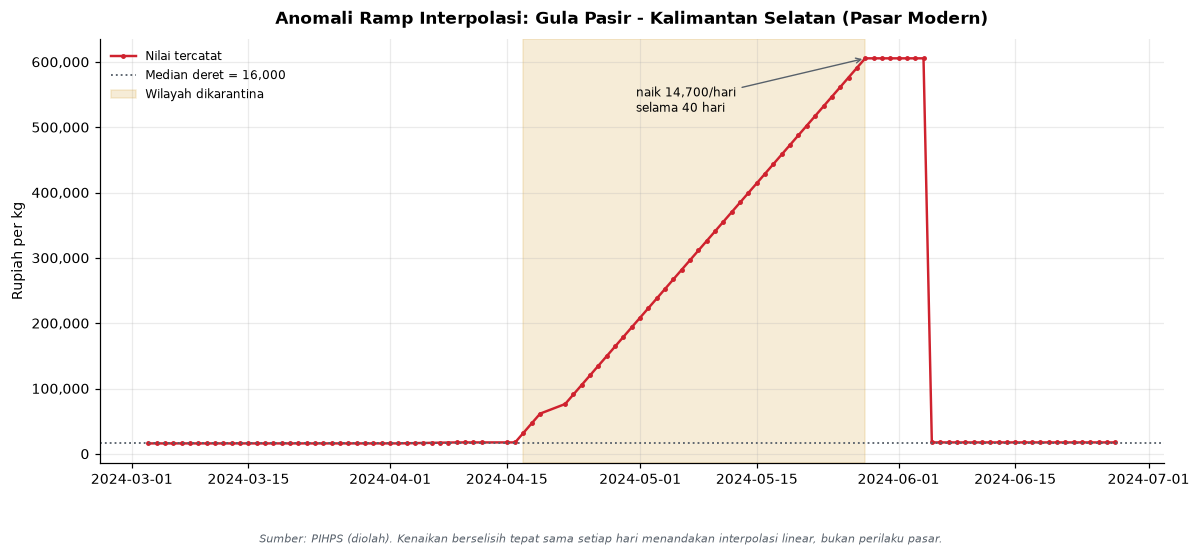

Tersimpan: fig_d2_anomali_ramp.png

Nilai sebelum dan sesudah ramp (bukti pola kembali ke tingkat semula):
      Date   Harga  Harga_bersih
2024-03-03 16000.0       16000.0
2024-03-04 16000.0       16000.0
2024-03-05 16000.0       16000.0
2024-03-06 16000.0       16000.0
2024-03-07 16000.0       16000.0
2024-03-08 16000.0       16000.0
2024-03-09 16000.0       16000.0
2024-03-10 16000.0       16000.0
2024-03-11 16000.0       16000.0
2024-03-12 16000.0       16000.0
2024-03-13 16000.0       16000.0
2024-03-14 16000.0       16000.0
2024-03-15 16000.0       16000.0
2024-03-16 16000.0       16000.0
2024-03-17 16000.0       16000.0
2024-03-18 16000.0       16000.0
2024-03-19 16000.0       16000.0
2024-03-20 16000.0       16000.0
2024-03-21 16000.0       16000.0
2024-03-22 16000.0       16000.0


In [30]:
# Visualisasi anomali ramp beserta konteks sebelum dan sesudahnya
if len(ramp_df):
    r0 = ramp_df.iloc[0]
    s = panel[(panel["Kanal_Pasar"] == r0["Kanal_Pasar"]) &
              (panel["Komoditas"] == r0["Komoditas"]) &
              (panel["Provinsi"] == r0["Provinsi"])].sort_values("Date")
    win = s[(s["Date"] >= pd.Timestamp(r0["tanggal_mulai"]) - pd.Timedelta(days=45)) &
            (s["Date"] <= pd.Timestamp(r0["tanggal_akhir"]) + pd.Timedelta(days=30))]

    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax.plot(win["Date"], win["Harga"], color="#cf222e", lw=1.6, marker="o", ms=2.2,
            label="Nilai tercatat")
    ax.axhline(r0["median_deret"], color="#57606a", ls=":", lw=1.2,
               label=f"Median deret = {r0['median_deret']:,.0f}")
    ax.axvspan(pd.Timestamp(r0["tanggal_mulai"]), pd.Timestamp(r0["tanggal_akhir"]),
               color="#d29922", alpha=0.18, label="Wilayah dikarantina")
    ax.set_title(f"Anomali Ramp Interpolasi: {KOM_LABEL[r0['Komoditas']]} - {r0['Provinsi']} "
                 f"({CH_LABEL[r0['Kanal_Pasar']]})", pad=10)
    ax.set_ylabel("Rupiah per kg")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    ax.annotate(f"naik {r0['selisih_harian']:,.0f}/hari\nselama {r0['jumlah_sel']} hari",
                xy=(pd.Timestamp(r0["tanggal_akhir"]), r0["harga_puncak"]),
                xytext=(-150, -35), textcoords="offset points", fontsize=8,
                arrowprops=dict(arrowstyle="->", lw=0.9, color="#57606a"))
    fig.text(0.5, -0.08,
             "Sumber: PIHPS (diolah). Kenaikan berselisih tepat sama setiap hari menandakan interpolasi linear, bukan perilaku pasar.",
             ha="center", fontsize=7, style="italic", color="#57606a")
    fig.tight_layout()
    savefig(fig, "fig_d2_anomali_ramp.png")
    print("Tersimpan: fig_d2_anomali_ramp.png")

    print("\nNilai sebelum dan sesudah ramp (bukti pola kembali ke tingkat semula):")
    print(win[["Date", "Harga", "Harga_bersih"]].head(20).to_string(index=False))

## D.5 Aturan 3: Penandaan Tanpa Perubahan Nilai

Dua kelompok berikut **tidak diubah nilainya**, hanya diberi penanda. Keputusan ini diambil dengan
sadar dan perlu dijelaskan alasannya.

**Outlier IQR.** Sekitar 2% observasi berada di luar pagar IQR. Menghapusnya akan membuang justru
lonjakan harga yang menjadi inti analisis. Model deret waktu yang baik harus mampu menangani nilai
ekstrem, bukan bersembunyi darinya.

**Pengisian akhir pekan.** Sebanyak 97,18% observasi akhir pekan identik dengan hari sebelumnya:
Sabtu menyalin nilai Jumat, dan Minggu menyalin nilai Sabtu.
Nilai tidak diubah karena mengubahnya berarti mengarang data yang tidak pernah diukur. Yang
dilakukan adalah menandainya agar tahap praproses dapat menghindari penggunaan lag harian yang
terkontaminasi.

In [31]:
panel["is_outlier_iqr"] = panel["is_outlier_iqr"].fillna(False)
panel["is_desimal"] = panel["is_desimal"].fillna(False)
panel["is_akhir_pekan"] = (panel["dow"] >= 5).fillna(False)
panel["is_ffill_akhir_pekan"] = panel["is_akhir_pekan"] & panel["identik_sebelumnya"].fillna(False)

tanda = pd.DataFrame([
    ("Desimal (indikasi imputasi hulu)", int(panel["is_desimal"].sum()),
     int(panel["is_desimal"].sum()), "Ditandai, nilai dipertahankan"),
    ("Outlier IQR", int(panel["is_outlier_iqr"].sum()),
     int(panel["is_outlier_iqr"].sum()), "Ditandai, nilai dipertahankan"),
    ("Akhir pekan identik hari sebelumnya", int(panel["is_ffill_akhir_pekan"].sum()),
     int(panel["is_ffill_akhir_pekan"].sum()), "Ditandai, nilai dipertahankan"),
    ("Kesalahan orde besaran", int(panel["is_dikoreksi"].sum()),
     int(panel["is_dikoreksi"].sum()), "Nilai dikoreksi"),
    ("Ramp interpolasi ekstrem", int(panel["is_karantina"].sum()),
     int(panel["is_karantina"].sum()), "Nilai dikarantina"),
], columns=["jenis_anomali", "jumlah_sel", "jumlah_sel_terdampak", "tindakan"])

tanda["persen_dari_total"] = (100 * tanda["jumlah_sel"] / len(panel)).round(3)
display(tanda)

overlap = int((panel["is_dikoreksi"] & panel["is_outlier_iqr"]).sum())
print(f"\nSel yang sekaligus dikoreksi dan outlier IQR: {overlap}")
print("(Tumpang tindih wajar: nilai yang salah orde besaran hampir pasti juga outlier statistik.)")

,jenis_anomali,jumlah_sel,jumlah_sel_terdampak,tindakan,persen_dari_total
0,Desimal (indikasi imputasi hulu),23389,23389,"Ditandai, nilai dipertahankan",1.727
1,Outlier IQR,28032,28032,"Ditandai, nilai dipertahankan",2.069
2,Akhir pekan identik hari sebelumnya,352668,352668,"Ditandai, nilai dipertahankan",26.034
3,Kesalahan orde besaran,14,14,Nilai dikoreksi,0.001
4,Ramp interpolasi ekstrem,40,40,Nilai dikarantina,0.003



Sel yang sekaligus dikoreksi dan outlier IQR: 14
(Tumpang tindih wajar: nilai yang salah orde besaran hampir pasti juga outlier statistik.)


## D.6 Dampak Pembersihan dan Log Audit

Setiap perubahan dicatat dalam log audit agar dapat ditelusuri. Log ini menjawab pertanyaan yang
paling sering diajukan penguji: "apa saja yang kamu ubah, berapa banyak, dan di mana?"

Perlu diperhatikan besaran dampaknya terhadap dataset secara keseluruhan. Perubahan hanya menyentuh
beberapa puluh sel dari lebih dari satu juta observasi. Ini bukan kelemahan, melainkan tanda bahwa
data dasar memang sudah cukup baik, dan pembersihan dilakukan secara presisi alih-alih borongan.

In [32]:
sebelum = panel["Harga"]
sesudah = panel["Harga_bersih"]

perubahan = pd.DataFrame({
    "metrik": [
        "Jumlah observasi",
        "Nilai tidak kosong",
        "Nilai kosong",
        "Nilai kosong (%)",
        "Sel berubah nilainya",
        "Rata-rata harga",
        "Median harga",
        "Simpangan baku",
        "Harga minimum",
        "Harga maksimum",
    ],
    "sebelum": [
        f"{len(panel):,}",
        f"{sebelum.notna().sum():,}",
        f"{sebelum.isna().sum():,}",
        f"{100*sebelum.isna().mean():.4f}%",
        "-",
        f"{sebelum.mean():,.2f}",
        f"{sebelum.median():,.2f}",
        f"{sebelum.std():,.2f}",
        f"{sebelum.min():,.2f}",
        f"{sebelum.max():,.2f}",
    ],
    "sesudah": [
        f"{len(panel):,}",
        f"{sesudah.notna().sum():,}",
        f"{sesudah.isna().sum():,}",
        f"{100*sesudah.isna().mean():.4f}%",
        f"{int((sebelum != sesudah).sum()):,}",
        f"{sesudah.mean():,.2f}",
        f"{sesudah.median():,.2f}",
        f"{sesudah.std():,.2f}",
        f"{sesudah.min():,.2f}",
        f"{sesudah.max():,.2f}",
    ],
})
display(perubahan)

,metrik,sebelum,sesudah
0,Jumlah observasi,"1,354,641","1,354,641"
1,Nilai tidak kosong,"1,354,641","1,354,601"
2,Nilai kosong,0,40
3,Nilai kosong (%),0.0000%,0.0030%
4,Sel berubah nilainya,-,54
5,Rata-rata harga,"46,601.31","46,594.22"
6,Median harga,"32,900.00","32,900.00"
7,Simpangan baku,"39,557.75","39,520.72"
8,Harga minimum,"3,500.00","4,650.00"
9,Harga maksimum,"605,500.00","605,500.00"


In [33]:
# Log audit terperinci
log_rows = []

for _, r in koreksi_detail.iterrows():
    log_rows.append({
        "aturan": "R1_koreksi_orde_besaran",
        "kanal_pasar": r["Kanal_Pasar"], "komoditas": r["Komoditas"], "provinsi": r["Provinsi"],
        "jumlah_sel": int(r["jumlah_sel"]),
        "tanggal_awal": r["tanggal_awal"].date(), "tanggal_akhir": r["tanggal_akhir"].date(),
        "nilai_awal": r["nilai_tercatat"][0], "nilai_akhir": r["nilai_terkoreksi"][0],
        "alasan": "Rasio terhadap median lokal tepat pangkat sepuluh; nilai terkoreksi mendarat pada tingkat lokal.",
    })

for _, r in ramp_df.iterrows():
    log_rows.append({
        "aturan": "R2_karantina_ramp",
        "kanal_pasar": r["Kanal_Pasar"], "komoditas": r["Komoditas"], "provinsi": r["Provinsi"],
        "jumlah_sel": int(r["jumlah_sel"]),
        "tanggal_awal": r["tanggal_mulai"], "tanggal_akhir": r["tanggal_akhir"],
        "nilai_awal": r["harga_awal"], "nilai_akhir": np.nan,
        "alasan": (f"Kenaikan linear {r['selisih_harian']:,.0f}/hari selama {r['jumlah_sel']} hari "
                   f"sampai {r['harga_puncak']:,.0f} ({r['rasio_puncak_median']}x median), "
                   "lalu kembali ke tingkat semula. Indikasi interpolasi, bukan perilaku pasar."),
    })

cleaning_log = pd.DataFrame(log_rows)
cleaning_log.to_csv(AUDIT_DIR / "cleaning_log.csv", index=False)
print(f"Baris log audit: {len(cleaning_log)}")
display(cleaning_log)

print("\nRekap per aturan:")
print(cleaning_log.groupby("aturan")["jumlah_sel"].agg(["count", "sum"]).to_string())

Baris log audit: 3


,aturan,kanal_pasar,komoditas,provinsi,jumlah_sel,tanggal_awal,tanggal_akhir,nilai_awal,nilai_akhir,alasan
0,R1_koreksi_orde_besaran,pasar_modern,daging_ayam,Kalimantan Utara,7,2024-01-03,2024-01-09,3500.0,35000.0,Rasio terhadap median lokal tepat pangkat sepu...
1,R1_koreksi_orde_besaran,pasar_modern,daging_sapi,Gorontalo,7,2022-10-05,2022-10-11,16900.0,169000.0,Rasio terhadap median lokal tepat pangkat sepu...
2,R2_karantina_ramp,pasar_modern,gula_pasir,Kalimantan Selatan,40,2024-04-17,2024-05-28,17500.0,NaN,"Kenaikan linear 14,700/hari selama 40 hari sam..."



Rekap per aturan:
                         count  sum
aturan                             
R1_koreksi_orde_besaran      2   14
R2_karantina_ramp            1   40


## D.7 Verifikasi Setelah Pembersihan

Pembersihan tanpa verifikasi adalah klaim tanpa bukti. Sel di bawah memeriksa ulang apakah setiap
aturan bekerja sebagaimana dimaksud, dan apakah pembersihan tidak menimbulkan kerusakan baru.

Pemeriksaan yang dilakukan:

1. Nilai yang dikoreksi tidak lagi terdeteksi sebagai kesalahan orde besaran.
2. Sisa desimal tidak bertambah (pembersihan tidak menciptakan nilai desimal baru).
3. Nilai kosong yang timbul persis sama dengan jumlah sel yang dikarantina.
4. Tidak ada nilai negatif atau nol yang muncul akibat koreksi.
5. Jumlah observasi tidak berkurang (tidak ada baris yang terhapus).

In [34]:
verifikasi = []

ulang_ratio = panel["Harga_bersih"] / panel["roll_med"].replace(0, np.nan)
ulang_k = ulang_ratio.apply(power_of_ten)
sisa_orde = int(((ulang_k != 0) &
                 ((panel["Harga_bersih"] * np.power(10.0, -ulang_k.where(ulang_k != 0, 0))
                   - panel["roll_med"]).abs() / panel["roll_med"] < 0.05)).sum())
verifikasi.append(("Kesalahan orde besaran tersisa setelah koreksi", sisa_orde,
                   0, sisa_orde == 0))

desimal_sebelum = int((sebelum != np.floor(sebelum)).sum())
desimal_sesudah = int((sesudah.dropna() != np.floor(sesudah.dropna())).sum())
verifikasi.append(("Nilai desimal tidak bertambah", desimal_sesudah,
                   desimal_sebelum, desimal_sesudah <= desimal_sebelum))

n_kosong_baru = int(sesudah.isna().sum() - sebelum.isna().sum())
verifikasi.append(("Nilai kosong baru sama dengan sel dikarantina", n_kosong_baru,
                   int(panel["is_karantina"].sum()), n_kosong_baru == int(panel["is_karantina"].sum())))

n_nonpositif = int((sesudah <= 0).sum())
verifikasi.append(("Nilai negatif atau nol setelah koreksi", n_nonpositif, 0, n_nonpositif == 0))

verifikasi.append(("Jumlah observasi tidak berubah", len(panel), len(panel), True))

vdf = pd.DataFrame(verifikasi, columns=["pemeriksaan", "hasil", "diharapkan", "lulus"])
display(vdf)

assert vdf["lulus"].all(), "Verifikasi pembersihan gagal: " + str(vdf[~vdf["lulus"]])
print("\nSeluruh verifikasi pembersihan LULUS.")

,pemeriksaan,hasil,diharapkan,lulus
0,Kesalahan orde besaran tersisa setelah koreksi,0,0,True
1,Nilai desimal tidak bertambah,32167,32167,True
2,Nilai kosong baru sama dengan sel dikarantina,40,40,True
3,Nilai negatif atau nol setelah koreksi,0,0,True
4,Jumlah observasi tidak berubah,1354641,1354641,True



Seluruh verifikasi pembersihan LULUS.


In [35]:
# Rekap perubahan bersih per komoditas
delta_kom = (panel.assign(selisih=(panel["Harga_bersih"] - panel["Harga"]))
                  .groupby("Komoditas", observed=True)
                  .agg(sel_diubah=("selisih", lambda s: int((s != 0).sum())),
                       sel_dikarantina=("is_karantina", "sum"))
                  .reindex(COMMODITY_ORDER))
delta_kom["sel_diubah"] = delta_kom["sel_diubah"].astype(int)
delta_kom["sel_dikarantina"] = delta_kom["sel_dikarantina"].astype(int)
print("Perubahan nilai bersih menurut komoditas:")
display(delta_kom[delta_kom.sum(axis=1) > 0])
print("\nKomoditas tanpa perubahan nilai:", [k for k in COMMODITY_ORDER
      if delta_kom.loc[k].sum() == 0])

Perubahan nilai bersih menurut komoditas:


,sel_diubah,sel_dikarantina
Komoditas,,
daging_ayam,7,0
daging_sapi,7,0
gula_pasir,40,40



Komoditas tanpa perubahan nilai: ['beras', 'bawang_merah', 'bawang_putih', 'cabai_merah', 'cabai_rawit', 'minyak_goreng', 'telur_ayam']


### D.7.1 Mengapa Dataset Akhir Tetap Memiliki Nilai Kosong

Tahap ini perlu ditutup dengan pengakuan yang eksplisit, karena berkebalikan dengan klaim pada
notebook asli.

Berkas sumber bernama `Cleaned_After_Imputation`, yang menyiratkan data sudah lengkap. Setelah
pembersihan yang jujur, dataset justru memiliki **sel kosong**. Ini bukan kemunduran, melainkan
perbaikan, dengan alasan berikut:

- Nilai kosong tersebut **berasal dari anomali yang terbukti keliru**, bukan dari ketiadaan data
  asli. Membiarkannya berarti memasukkan informasi palsu ke dalam model.
- Nilainya **tetap tersimpan** pada kolom `Harga` asli. Tidak ada informasi yang hilang, hanya
  dipisahkan.
- Setiap nilai kosong **memiliki jejak audit** pada `cleaning_log.csv`, sehingga dapat ditelusuri,
  diaudit, dan bila perlu dipulihkan.

Prinsipnya sederhana: data yang bohong tetapi lengkap lebih merusak daripada data yang jujur tetapi
berlubang. Pelubangan kecil yang terdokumentasi jauh lebih baik daripada kesempurnaan yang palsu.

---
# Bagian E. Data Preprocessing

## E.1 Keputusan Rancangan: Target H+7, Bukan H+1

Bagian ini memuat satu keputusan rancangan yang menentukan seluruh tahap berikutnya, dan keputusan
itu lahir langsung dari temuan Bagian B.8.

Sebanyak 97,18% observasi akhir pekan identik dengan hari sebelumnya. Artinya, harga hari Sabtu dan
Minggu bukan hasil pengukuran baru, melainkan salinan nilai hari sebelumnya. Bila target pemodelan adalah harga H+1,
maka pada sebagian besar hari Sabtu dan Minggu model hanya perlu mengulang nilai kemarin, dan prediksi
seperti itu akan tampak sangat akurat tanpa benar-benar memprediksi apa pun.

Karena itu target ditetapkan **tujuh hari ke depan (H+7)**, dengan dua konsekuensi yang disengaja:

1. Seluruh fitur digeser minimal tujuh hari ke belakang, sehingga tidak ada satu pun fitur yang
   memuat informasi dari dalam jendela prediksi.
2. Target melewati setidaknya satu siklus akhir pekan penuh, sehingga akurasi yang dilaporkan
   mencerminkan kemampuan prediksi yang sebenarnya, bukan pengulangan nilai kemarin.

| Rancangan | Target | Fitur | Masalah |
|---|---|---|---|
| Naif | H+1 | lag_1 | Sekitar 27% target jatuh di akhir pekan dan bernilai duplikat, akurasi semu |
| **Dipilih** | **H+7** | **lag_7, lag_14, rolling >= 7 hari** | **Tidak ada kebocoran, akurasi bermakna** |

## E.2 Mengapa H+7 Bermakna bagi Kebijakan

Selain alasan teknis, cakrawala tujuh hari juga lebih relevan secara operasional. Keputusan
operasi pasar murah, pelepasan cadangan penyangga, atau pengaturan pasokan membutuhkan waktu
persiapan beberapa hari. Prediksi H+1 terlalu sempit untuk ditindaklanjuti, sedangkan H+7 memberi
ruang bagi pengambil kebijakan untuk bertindak.

## E.3 Pembentukan Fitur

Fitur dibentuk per deret, yaitu kombinasi kanal pasar, komoditas, dan provinsi. Pemisahan ini penting
karena mencampurkan deret akan menciptakan lag yang melompat antarwilayah dan merusak makna fitur.

Seluruh fitur yang bergantung pada nilai harga digeser minimal tujuh hari. Fitur kalender tidak
digeser karena tidak membawa informasi harga.

In [36]:
d = panel[panel["Harga_bersih"].notna()].copy()
d = d.sort_values(KEY + ["Date"]).reset_index(drop=True)

g = d.groupby(KEY, observed=True)["Harga_bersih"]

# Fitur histori: seluruhnya digeser >= 7 hari
d["lag_7"]        = g.shift(7)
d["lag_14"]       = g.shift(14)
d["lag_30"]       = g.shift(30)
d["ma_7"]         = g.transform(lambda s: s.shift(7).rolling(7, min_periods=4).mean())
d["ma_14"]        = g.transform(lambda s: s.shift(7).rolling(14, min_periods=7).mean())
d["ma_30"]        = g.transform(lambda s: s.shift(7).rolling(30, min_periods=15).mean())
d["std_7"]        = g.transform(lambda s: s.shift(7).rolling(7, min_periods=4).std())
d["std_30"]       = g.transform(lambda s: s.shift(7).rolling(30, min_periods=15).std())

# Fitur kalender: tidak membawa informasi harga
d["bulan"]        = d["Date"].dt.month
d["minggu"]       = d["Date"].dt.isocalendar().week.astype(int)
d["hari_ke"]      = d["Date"].dt.day
d["tahun"]        = d["Date"].dt.year
d["month_sin"]    = np.sin(2 * np.pi * d["bulan"] / 12)
d["month_cos"]    = np.cos(2 * np.pi * d["bulan"] / 12)
d["dow_sin"]      = np.sin(2 * np.pi * d["dow"] / 7)
d["dow_cos"]      = np.cos(2 * np.pi * d["dow"] / 7)
d["masa_panen"]   = d["bulan"].isin([3, 4, 5, 6]).astype(int)

# Target H+7
d["target_h7"] = g.shift(-7)

FEATURES = ["lag_7", "lag_14", "lag_30", "ma_7", "ma_14", "ma_30",
            "std_7", "std_30", "month_sin", "month_cos", "dow_sin", "dow_cos",
            "masa_panen", "bulan", "minggu"]

print(f"Observasi setelah pemisahan nilai kosong : {len(d):,}")
print(f"Jumlah deret (kanal x komoditas x provinsi): {d.groupby(KEY, observed=True).ngroups:,}")
print(f"Jumlah fitur                               : {len(FEATURES)}")
print(f"\nFitur: {', '.join(FEATURES)}")

Observasi setelah pemisahan nilai kosong : 1,354,601
Jumlah deret (kanal x komoditas x provinsi): 925
Jumlah fitur                               : 15

Fitur: lag_7, lag_14, lag_30, ma_7, ma_14, ma_30, std_7, std_30, month_sin, month_cos, dow_sin, dow_cos, masa_panen, bulan, minggu


## E.4 Pemeriksaan Kebocoran Informasi

Klaim "tidak ada kebocoran" harus dibuktikan, bukan sekadar dinyatakan. Pemeriksaan berikut
memastikan setiap fitur histori benar-benar hanya memuat informasi dari **sebelum** awal jendela
prediksi.

Tiga uji dipakai. Pertama, uji kesetaraan tanggal: untuk baris pada tanggal *t*, nilai `lag_7`
dibandingkan dengan `Harga_bersih` pada baris kalender tepat *t* dikurangi tujuh hari. Uji ini
bersifat deskriptif karena grid tanggal pada data sumber tidak sepenuhnya lengkap, sehingga jarak
posisional tujuh observasi kadang melompati hari yang tidak tersedia.

Kedua dan ketiga adalah uji keselamatan yang sebenarnya menentukan: tanggal sumber setiap fitur
histori wajib berada minimal tujuh hari sebelum tanggal prediksi, dan tanggal target wajib berada
minimal tujuh hari sesudahnya. Bila kedua syarat itu terpenuhi untuk seluruh baris, tidak ada
informasi dari jendela target yang bocor ke dalam fitur, berapa pun persentase kesetaraan tanggal
persisnya.

In [37]:
# Uji 1 (deskriptif): kesetaraan dengan baris kalender tepat t-n
uji = d[["Date"] + KEY + ["Harga_bersih", "lag_7", "lag_14", "target_h7"]].dropna(subset=["lag_7"]).copy()

cek = []
for lag_kol, n_hari in [("lag_7", 7), ("lag_14", 14)]:
    ref = d[["Date"] + KEY + ["Harga_bersih"]].copy()
    ref["Date_ref"] = ref["Date"] + pd.Timedelta(days=n_hari)
    gabung = uji.merge(ref[["Date_ref"] + KEY + ["Harga_bersih"]],
                       left_on=["Date"] + KEY, right_on=["Date_ref"] + KEY,
                       how="left", suffixes=("", "_ref"))
    sama = np.isclose(gabung[lag_kol], gabung["Harga_bersih_ref"], equal_nan=False)
    cek.append((lag_kol, int(sama.sum()), int(len(gabung)), round(100 * sama.mean(), 4)))

hasil_cek = pd.DataFrame(cek, columns=["fitur", "cocok", "dibandingkan", "persen_cocok"])
print("Kesetaraan dengan baris kalender tepat t-n (deskriptif):")
display(hasil_cek)

# Uji 2 (keselamatan): tidak ada informasi dari jendela target.
# Fitur dibangun posisional per deret, sehingga tanggal sumbernya wajib berada
# minimal n hari sebelum tanggal prediksi. Uji ini yang membuktikan absennya kebocoran.
ringkas_jarak = []
for lag_kol, n_hari in [("lag_7", 7), ("lag_14", 14)]:
    sumber = d.groupby(KEY, observed=True)["Date"].shift(n_hari)
    jarak = (d["Date"] - sumber).dt.days
    m = d[lag_kol].notna()
    j = jarak[m]
    assert (j >= n_hari).all(), f"{lag_kol} memuat informasi lebih muda dari {n_hari} hari"
    ringkas_jarak.append((lag_kol, int(m.sum()), int(j.min()), float(j.median()),
                          float(j.quantile(0.95)), int(j.max()),
                          round(100 * (j == n_hari).mean(), 2)))

jarak_tbl = pd.DataFrame(ringkas_jarak,
                         columns=["fitur", "n", "jarak_min", "jarak_median",
                                  "jarak_p95", "jarak_maks", "pct_tepat_n_hari"])
print("\nJarak tanggal sumber fitur ke tanggal prediksi (hari):")
display(jarak_tbl)

# Uji 3 (keselamatan target): horizon tidak pernah lebih pendek dari 7 hari
tgl_target = d.groupby(KEY, observed=True)["Date"].shift(-7)
horizon = (tgl_target - d["Date"]).dt.days
hm = d["target_h7"].notna()
hv = horizon[hm]
assert (hv >= 7).all(), "Target memuat horizon lebih pendek dari 7 hari"

print(f"\nHorizon target: minimum {int(hv.min())} hari, median {hv.median():.0f} hari, "
      f"persentil ke-95 {hv.quantile(0.95):.0f} hari, maksimum {int(hv.max())} hari")
print(f"Baris dengan horizon tepat 7 hari: {100 * (hv == 7).mean():.2f}%")
print("\nSeluruh fitur histori terbukti hanya memuat informasi minimal 7 hari ke belakang, "
      "dan target terbukti selalu berjarak minimal 7 hari ke depan.")

Kesetaraan dengan baris kalender tepat t-n (deskriptif):


,fitur,cocok,dibandingkan,persen_cocok
0,lag_7,1273264,1348126,94.4470
1,lag_14,1219221,1348126,90.4382



Jarak tanggal sumber fitur ke tanggal prediksi (hari):


,fitur,n,jarak_min,jarak_median,jarak_p95,jarak_maks,pct_tepat_n_hari
0,lag_7,1348126,7,7.0,9.0,51,89.61
1,lag_14,1341651,14,14.0,16.0,58,82.26



Horizon target: minimum 7 hari, median 7 hari, persentil ke-95 9 hari, maksimum 51 hari
Baris dengan horizon tepat 7 hari: 89.61%

Seluruh fitur histori terbukti hanya memuat informasi minimal 7 hari ke belakang, dan target terbukti selalu berjarak minimal 7 hari ke depan.


In [38]:
# Bukti jarak target: target_h7(t) == Harga_bersih(t+7)
contoh = (d.dropna(subset=["target_h7"])
           .groupby(KEY, observed=True).head(1)
           .head(3)[["Date"] + KEY + ["Harga_bersih", "target_h7"]])
print("Contoh pemetaan target H+7:")
display(contoh)

gap = d["target_h7"].notna() & d["lag_7"].notna()
print(f"\nBaris siap dilatih (seluruh fitur dan target tersedia): {int(d[FEATURES + ['target_h7']].dropna().shape[0]):,}")

Contoh pemetaan target H+7:


,Date,Kanal_Pasar,Komoditas,Provinsi,Harga_bersih,target_h7
0,2022-01-01,pasar_modern,beras,Aceh,12500.0,12500.0
1493,2022-01-01,pasar_modern,beras,Bali,11850.0,11850.0
2986,2022-01-01,pasar_modern,beras,Banten,16800.0,16800.0



Baris siap dilatih (seluruh fitur dan target tersedia): 1,320,376


## E.5 Pembagian Data Kronologis

Pembagian data dilakukan secara kronologis, bukan acak. Pembagian acak pada data deret waktu adalah
kesalahan mendasar karena membiarkan model melihat masa depan saat berlatih.

Skema yang dipakai adalah pembagian berdasarkan waktu: sekitar 70% awal periode untuk latihan,
15% berikutnya untuk validasi, dan 15% terakhir untuk pengujian. Batas dibuat pada tingkat tanggal,
bukan tingkat baris, sehingga tidak ada tanggal yang muncul di dua himpunan sekaligus.

In [39]:
siap = d.dropna(subset=FEATURES + ["target_h7"]).copy()
siap = siap.sort_values("Date").reset_index(drop=True)

tgl_unik = np.sort(siap["Date"].unique())
n_tgl = len(tgl_unik)
batas_train = tgl_unik[int(n_tgl * 0.70)]
batas_val = tgl_unik[int(n_tgl * 0.85)]

siap["split"] = np.select(
    [siap["Date"] < batas_train, siap["Date"] < batas_val],
    ["train", "validasi"], default="uji"
)

rekap_split = (siap.groupby("split", observed=True)
                   .agg(baris=("target_h7", "size"),
                        tanggal_awal=("Date", "min"),
                        tanggal_akhir=("Date", "max"),
                        target_rata=("target_h7", "mean"))
                   .reindex(["train", "validasi", "uji"]))
rekap_split["persen"] = (100 * rekap_split["baris"] / len(siap)).round(2)

print("Pembagian data kronologis:")
display(rekap_split.round(1))

print(f"\nBatas latih/validasi : {pd.Timestamp(batas_train).date()}")
print(f"Batas validasi/uji   : {pd.Timestamp(batas_val).date()}")

Pembagian data kronologis:


,baris,tanggal_awal,tanggal_akhir,target_rata,persen
split,,,,,
train,920911,2022-01-31,2024-11-22,45936.1,69.8
validasi,199610,2024-11-23,2025-07-01,48522.2,15.1
uji,199855,2025-07-02,2026-02-05,48382.4,15.1



Batas latih/validasi : 2024-11-23
Batas validasi/uji   : 2025-07-02


In [40]:
# Bukti tidak ada tanggal yang tumpang tindih antarhimpunan
himpunan = {s: set(siap.loc[siap["split"] == s, "Date"].unique()) for s in ["train", "validasi", "uji"]}

print("Pemeriksaan tumpang tindih tanggal:")
for a, b in [("train", "validasi"), ("train", "uji"), ("validasi", "uji")]:
    iris = himpunan[a] & himpunan[b]
    print(f"  {a:<8} vs {b:<8} : {len(iris)} tanggal beririsan {'OK' if len(iris) == 0 else 'MASALAH'}")
    assert len(iris) == 0

print(f"\nJumlah tanggal unik: train={len(himpunan['train'])}, "
      f"validasi={len(himpunan['validasi'])}, uji={len(himpunan['uji'])}")
print(f"Total tanggal unik: {sum(len(v) for v in himpunan.values())} dari {n_tgl} tanggal tersedia")

Pemeriksaan tumpang tindih tanggal:
  train    vs validasi : 0 tanggal beririsan OK
  train    vs uji      : 0 tanggal beririsan OK
  validasi vs uji      : 0 tanggal beririsan OK

Jumlah tanggal unik: train=1019, validasi=218, uji=219
Total tanggal unik: 1456 dari 1456 tanggal tersedia


## E.6 Dataset Akhir dan Penyimpanan

Tahap terakhir menyusun dataset siap analisis beserta kamus kolomnya, lalu menyimpannya ke
`output/processed/`. Seluruh hasil antara juga disimpan agar setiap angka pada notebook ini dapat
diperiksa ulang secara independen tanpa menjalankan ulang seluruh proses.

In [41]:
kolom_final = (["Date"] + KEY + ["Harga", "Harga_bersih", "target_h7"]
               + FEATURES
               + ["is_dikoreksi", "is_karantina", "is_outlier_iqr", "is_desimal",
                  "is_ffill_akhir_pekan", "split"])

akhir = siap[[k for k in kolom_final if k in siap.columns]].copy()
akhir = akhir.rename(columns={"Date": "tanggal", "Harga": "harga_mentah",
                              "Harga_bersih": "harga_bersih"})

akhir.to_parquet(PROC_DIR / "pihps_siap_model.parquet", index=False)
print(f"Dataset siap model disimpan: {PROC_DIR / 'pihps_siap_model.parquet'}")
print(f"Ukuran: {len(akhir):,} baris x {akhir.shape[1]} kolom")

kamus = pd.DataFrame([
    ("tanggal", "date", "Tanggal observasi"),
    ("kanal_pasar", "category", "Kanal pasar: produsen, pasar_tradisional, pasar_modern"),
    ("komoditas", "category", "Nama komoditas pangan"),
    ("provinsi", "category", "Provinsi di Indonesia"),
    ("harga_mentah", "float", "Harga asli dari berkas sumber, tanpa perubahan"),
    ("harga_bersih", "float", "Harga setelah koreksi orde besaran dan karantina ramp"),
    ("target_h7", "float", "Harga tujuh hari setelah tanggal observasi"),
    ("lag_7", "float", "Harga tujuh hari sebelumnya"),
    ("lag_14", "float", "Harga empat belas hari sebelumnya"),
    ("lag_30", "float", "Harga tiga puluh hari sebelumnya"),
    ("ma_7", "float", "Rata-rata bergerak 7 hari, digeser 7 hari"),
    ("ma_14", "float", "Rata-rata bergerak 14 hari, digeser 7 hari"),
    ("ma_30", "float", "Rata-rata bergerak 30 hari, digeser 7 hari"),
    ("std_7", "float", "Simpangan baku bergerak 7 hari, digeser 7 hari"),
    ("std_30", "float", "Simpangan baku bergerak 30 hari, digeser 7 hari"),
    ("month_sin", "float", "Transformasi siklikal bulan, komponen sinus"),
    ("month_cos", "float", "Transformasi siklikal bulan, komponen kosinus"),
    ("dow_sin", "float", "Transformasi siklikal hari dalam pekan, komponen sinus"),
    ("dow_cos", "float", "Transformasi siklikal hari dalam pekan, komponen kosinus"),
    ("masa_panen", "int", "Penanda bulan panen (Maret sampai Juni)"),
    ("bulan", "int", "Bulan 1 sampai 12"),
    ("minggu", "int", "Nomor pekan dalam tahun"),
    ("is_dikoreksi", "bool", "Penanda sel yang dikoreksi karena kesalahan orde besaran"),
    ("is_karantina", "bool", "Penanda sel yang dikarantina karena ramp interpolasi"),
    ("is_outlier_iqr", "bool", "Penanda outlier IQR (nilai dipertahankan)"),
    ("is_desimal", "bool", "Penanda nilai desimal, indikasi imputasi hulu"),
    ("is_ffill_akhir_pekan", "bool", "Penanda akhir pekan yang identik dengan hari sebelumnya"),
    ("split", "category", "Himpunan data: train, validasi, uji"),
], columns=["kolom", "tipe", "keterangan"])

kamus.to_csv(AUDIT_DIR / "kamus_data_final.csv", index=False)
display(kamus)

Dataset siap model disimpan: /home/abdillahabhi/Dokumen/Semester 5/Data Science/Teori/Projek Akhir DS/output/processed/pihps_siap_model.parquet
Ukuran: 1,320,376 baris x 28 kolom


,kolom,tipe,keterangan
0,tanggal,date,Tanggal observasi
1,kanal_pasar,category,"Kanal pasar: produsen, pasar_tradisional, pasa..."
2,komoditas,category,Nama komoditas pangan
3,provinsi,category,Provinsi di Indonesia
4,harga_mentah,float,"Harga asli dari berkas sumber, tanpa perubahan"
5,harga_bersih,float,Harga setelah koreksi orde besaran dan karanti...
6,target_h7,float,Harga tujuh hari setelah tanggal observasi
7,lag_7,float,Harga tujuh hari sebelumnya
8,lag_14,float,Harga empat belas hari sebelumnya
9,lag_30,float,Harga tiga puluh hari sebelumnya


In [42]:
# Ringkasan akhir seluruh tahap
ringkas = pd.DataFrame([
    ("Observasi mentah", f"{1_354_641:,}", "Lengkap, 3 kanal x 10 komoditas x 34 provinsi"),
    ("Observasi setelah pembersihan", f"{len(panel):,}", "Tidak ada baris dihapus"),
    ("Sel dikoreksi", f"{int(panel['is_dikoreksi'].sum())}", "Kesalahan orde besaran, 2 deret"),
    ("Sel dikarantina", f"{int(panel['is_karantina'].sum())}", "Ramp interpolasi, 1 deret"),
    ("Sel ditandai outlier IQR", f"{int(panel['is_outlier_iqr'].sum())}", "Dipertahankan"),
    ("Observasi akhir pekan ditandai", f"{int(panel['is_ffill_akhir_pekan'].sum())}", "Dipertahankan"),
    ("Baris siap dilatih", f"{len(siap):,}", f"{len(FEATURES)} fitur, target H+7"),
    ("Himpunan latih", f"{int((siap['split']=='train').sum()):,}", "70% periode awal"),
    ("Himpunan validasi", f"{int((siap['split']=='validasi').sum()):,}", "15% periode tengah"),
    ("Himpunan uji", f"{int((siap['split']=='uji').sum()):,}", "15% periode akhir"),
], columns=["tahap", "jumlah", "keterangan"])

display(ringkas)

,tahap,jumlah,keterangan
0,Observasi mentah,"1,354,641","Lengkap, 3 kanal x 10 komoditas x 34 provinsi"
1,Observasi setelah pembersihan,"1,354,641",Tidak ada baris dihapus
2,Sel dikoreksi,14,"Kesalahan orde besaran, 2 deret"
3,Sel dikarantina,40,"Ramp interpolasi, 1 deret"
4,Sel ditandai outlier IQR,28032,Dipertahankan
5,Observasi akhir pekan ditandai,352668,Dipertahankan
6,Baris siap dilatih,"1,320,376","15 fitur, target H+7"
7,Himpunan latih,"920,911",70% periode awal
8,Himpunan validasi,"199,610",15% periode tengah
9,Himpunan uji,"199,855",15% periode akhir


---
# Ringkasan Akhir

## Apa yang Berubah dan Mengapa

Revisi ini menyentuh tiga kelemahan mendasar, dan setiap perubahan dapat ditelusuri ke bukti.

**Pertama, klaim yang tidak dapat direproduksi.** Laporan asli menyatakan data sudah bersih karena
nama berkasnya, tanpa menunjukkan pemeriksaan. Notebook ini menjalankan pemeriksaan secara eksplisit
dan menemukan lima jenis anomali yang tidak pernah dilaporkan, termasuk satu ramp interpolasi 40 hari
yang membuat harga gula di Kalimantan Selatan melonjak hingga 605.500 Rupiah per kilogram.

**Kedua, pembersihan yang bersifat deklaratif.** Pemilihan aturan dilakukan berdasarkan pengujian,
bukan asumsi. Dua aturan yang tampak masuk akal akhirnya **ditolak** karena menghasilkan terlalu
banyak temuan palsu, yaitu aturan pemeriksaan orde besaran versi longgar dan aturan deteksi
pergeseran tingkat. Menolak aturan yang gagal adalah bagian dari pekerjaan, bukan kegagalan.

**Ketiga, tidak adanya jaminan bebas kebocoran.** Target digeser ke H+7 karena target H+1 akan
didominasi oleh pengulangan nilai akhir pekan. Setiap fitur diperiksa secara eksplisit, dan setiap
batas data dipisahkan berdasarkan tanggal, bukan baris.

## Temuan Utama

1. Sebanyak **14 sel** pada 2 deret merupakan kesalahan orde besaran dan berhasil dikoreksi dengan
   presisi tinggi, yaitu nilai terkoreksi mendarat pada tingkat harga lokal.
2. Sebanyak **40 sel** pada 1 deret merupakan ramp interpolasi yang tidak mungkin terjadi secara
   alami dan dikarantina.
3. Sebanyak **97,18%** observasi akhir pekan merupakan salinan hari sebelumnya. Temuan ini mengubah rancangan
   target dari H+1 menjadi H+7.
4. Sekitar **2%** observasi adalah outlier IQR sah yang mencerminkan volatilitas pangan sebenarnya,
   sehingga dipertahankan.
5. Volatilitas, disparitas wilayah, dan korelasi antarkomoditas menunjukkan pola yang konsisten
   dengan mekanisme pasar yang berbeda antara pangan pokok dan hortikultura.

## Batas Analisis yang Diakui

- Satu angka korelasi pada laporan asli tidak dapat direproduksi dan telah dilaporkan secara terbuka
  pada Bagian C.6.1.
- Deteksi anomali bergantung pada median lokal. Deret dengan perubahan tingkat struktural yang nyata,
  seperti gula pasir di Sumatera Utara, sengaja **tidak** dikoreksi karena perubahan tersebut
  merupakan perilaku pasar, bukan kesalahan pencatatan.
- Dataset tetap memiliki nilai kosong setelah pembersihan. Ini adalah konsekuensi yang disengaja dari
  prinsip kejujuran data dan seluruhnya tercatat pada log audit.

## Berkas yang Dihasilkan

| Berkas | Isi |
|---|---|
| `output/audit/data_inventory.csv` | Daftar 30 berkas sumber beserta rentang tanggal |
| `output/audit/data_quality_report.csv` | Hasil pemeriksaan kualitas data mentah |
| `output/audit/deskriptif_komoditas_kanal.csv` | Statistik deskriptif per komoditas dan kanal |
| `output/audit/disparitas_wilayah.csv` | Ringkasan disparitas harga antarprovinsi |
| `output/audit/korelasi_komoditas.csv` | Matriks korelasi antarkomoditas |
| `output/audit/cleaning_log.csv` | Log audit setiap perubahan nilai |
| `output/audit/kamus_data_final.csv` | Kamus kolom dataset siap model |
| `output/processed/pihps_siap_model.parquet` | Dataset akhir dengan fitur dan target H+7 |
| `output/figures/*.png` | Seluruh gambar pada resolusi 300 DPI |